In [2]:
%pip install pandas
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
from pathlib import Path

carpeta = Path(r"C:\Users\Lenovo _ LeGion\Documents\Universidad\Trabajo de Graduacion\Latex\PGL\raw results\Metricas\Convertidos")

# Buscar todos los CSV de interacciones, incluso en subcarpetas
archivos = sorted(carpeta.rglob("*_interacciones.csv"))

print(f"Archivos encontrados: {len(archivos)}")

# Leer todos los archivos
dataframes = []

for archivo in archivos:
    df = pd.read_csv(archivo, encoding="utf-8-sig")

    # Guardar de qué archivo proviene cada fila
    df["ArchivoOrigen"] = archivo.name

    dataframes.append(df)

# Unir los datos
if not dataframes:
    raise FileNotFoundError("No se encontraron archivos de interacciones")

df_final = pd.concat(dataframes, ignore_index=True)

# Guardar CSV unificado
salida = Path(r"C:\Users\Lenovo _ LeGion\Documents\Universidad\Trabajo de Graduacion\Latex\PGL\raw results") / "interacciones_unificadas.csv"
df_final.to_csv(salida, index=False, encoding="utf-8-sig")

print(f"Total de interacciones: {len(df_final)}")
print(f"Participantes: {df_final['Participante'].nunique()}")
print(f"CSV guardado en: {salida}")

Archivos encontrados: 34
Total de interacciones: 5048
Participantes: 34
CSV guardado en: C:\Users\Lenovo _ LeGion\Documents\Universidad\Trabajo de Graduacion\Latex\PGL\raw results\interacciones_unificadas.csv


In [4]:
# Número de interacciones por participante
df_final.groupby("Participante").size()

Participante
P001     132
P0011    138
P002     165
P003     169
P004     206
P005     154
P006     181
P007     109
P008     128
P010     115
P012     159
P013     192
P014     102
P015     132
P016     132
P017     138
P018     186
P019     145
P020     111
P021     152
P022     185
P023     121
P024     193
P025     147
P026     223
P027     117
P028     112
P029     110
P030     135
P031     181
P032     127
P033     131
P034     204
P036     116
dtype: int64

In [5]:
df_final.head(10)

,IdEvento,Participante,FechaHora,Minijuego,TipoAccion,Resultado,Dificultad,TiempoEsperado_s,TiempoReal_s,DesfaseTiming_s,ErrorTiming_s,TiempoReaccion_s,PrecisionEspacial,PrecisionDireccion,ManoCorrecta,LineaOrigen,ArchivoOrigen
0,2,P0011,2026-10-02 14:30:47.911,Alex,HammerTouch,Success,Normal,1.664,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7,Metrics_P0011_2026-10-02_14-30-44_interaccione...
1,4,P0011,2026-10-02 14:30:48.674,Alex,HammerTouch,Success,Normal,2.432,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9,Metrics_P0011_2026-10-02_14-30-44_interaccione...
2,5,P0011,2026-10-02 14:30:48.729,Alex,HammerTouch,Success,Normal,2.432,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10,Metrics_P0011_2026-10-02_14-30-44_interaccione...
3,6,P0011,2026-10-02 14:30:49.440,Alex,HammerHit,Success,Normal,3.200,3.2115,0.0115,0.0115,NaN,NaN,NaN,NaN,11,Metrics_P0011_2026-10-02_14-30-44_interaccione...
4,7,P0011,2026-10-02 14:30:49.494,Alex,HammerTouch,Success,Normal,3.200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12,Metrics_P0011_2026-10-02_14-30-44_interaccione...
5,8,P0011,2026-10-02 14:30:50.204,Alex,HammerHit,Failed,Normal,3.968,3.9759,0.0079,0.0079,NaN,NaN,NaN,NaN,13,Metrics_P0011_2026-10-02_14-30-44_interaccione...
6,9,P0011,2026-10-02 14:30:50.522,Alex,HammerTouch,Missed,Normal,3.968,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14,Metrics_P0011_2026-10-02_14-30-44_interaccione...
7,10,P0011,2026-10-02 14:30:50.954,Alex,HammerHit,Success,Normal,4.736,4.7261,-0.0099,0.0099,NaN,NaN,NaN,NaN,15,Metrics_P0011_2026-10-02_14-30-44_interaccione...
8,11,P0011,2026-10-02 14:30:50.996,Alex,HammerTouch,Success,Normal,4.736,NaN,NaN,NaN,NaN,NaN,NaN,NaN,16,Metrics_P0011_2026-10-02_14-30-44_interaccione...
9,12,P0011,2026-10-02 14:30:51.705,Alex,HammerHit,Success,Normal,5.504,5.4766,-0.0274,0.0274,NaN,NaN,NaN,NaN,17,Metrics_P0011_2026-10-02_14-30-44_interaccione...


In [6]:
import pandas as pd

# Filtrar los tres minijuegos
minijuegos = ["Jeremy", "Shipi", "JuanAndres"]

df = df_final[
    df_final["Minijuego"].isin(minijuegos)
].copy()

# Convertir precisión de dirección a valores numéricos
df["PrecisionDireccion"] = pd.to_numeric(
    df["PrecisionDireccion"], errors="coerce"
)

# Convertir True = 1 y False = 0
df["ManoCorrectaNum"] = (
    df["ManoCorrecta"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map({"true": 1, "false": 0})
)

# Agrupar por participante y minijuego
resultados = df.groupby(
    ["Participante", "Minijuego"], as_index=False
).agg(
    SumaDireccion=("PrecisionDireccion", "sum"),
    TotalDireccion=("PrecisionDireccion", "count"),
    SumaMano=("ManoCorrectaNum", "sum"),
    TotalMano=("ManoCorrectaNum", "count")
)

# Calcular los porcentajes
resultados["PrecisionDireccion_%"] = (
    resultados["SumaDireccion"] /
    resultados["TotalDireccion"].replace(0, float("nan")) * 100
).round(2)

resultados["ManoCorrecta_%"] = (
    resultados["SumaMano"] /
    resultados["TotalMano"].replace(0, float("nan")) * 100
).round(2)

# Seleccionar columnas finales
resultados_finales = resultados[
    ["Participante", "Minijuego",
     "PrecisionDireccion_%", "ManoCorrecta_%"]
]

display(resultados_finales)

,Participante,Minijuego,PrecisionDireccion_%,ManoCorrecta_%
0,P001,Jeremy,75.00,87.50
1,P001,JuanAndres,42.86,50.00
2,P001,Shipi,18.18,NaN
3,P0011,Jeremy,71.43,85.71
4,P0011,JuanAndres,31.25,68.75
...,...,...,...,...
97,P034,JuanAndres,72.22,88.89
98,P034,Shipi,58.82,NaN
99,P036,Jeremy,87.50,100.00
100,P036,JuanAndres,38.89,66.67


In [7]:
import pandas as pd

# Orden deseado de los minijuegos
orden = {
    "Shipi": 0,
    "JuanAndres": 1,
    "Jeremy": 2
}

nombres = {
    "Shipi": "Shipi",
    "JuanAndres": "Juan Andres",
    "Jeremy": "Jeremy"
}

# Ordenar por participante y minijuego
df_latex = resultados_finales.copy()
df_latex["Orden"] = df_latex["Minijuego"].map(orden)
df_latex = df_latex.sort_values(["Participante", "Orden"])

# Formatear porcentajes
def porcentaje(valor):
    if pd.isna(valor):
        return "---"
    return f"{valor:.2f}\\%"

# Generar filas LaTeX
filas = []
participante_anterior = None

for _, fila in df_latex.iterrows():
    participante = fila["Participante"]
    minijuego = nombres[fila["Minijuego"]]

    # Separar participantes con una línea vacía
    if participante_anterior is not None and participante != participante_anterior:
        filas.append("")

    direccion = porcentaje(fila["PrecisionDireccion_%"])
    mano = porcentaje(fila["ManoCorrecta_%"])

    if minijuego == "Shipi":
        mano = "---"

    linea = (
        f"{participante} & {minijuego:<11} & "
        f"{direccion} & {mano} " + r"\\ \hline"
    )

    filas.append(linea)
    participante_anterior = participante

# Mostrar resultado
latex_tabla = "\n".join(filas)
print(latex_tabla)

P001 & Shipi       & 18.18\% & --- \\ \hline
P001 & Juan Andres & 42.86\% & 50.00\% \\ \hline
P001 & Jeremy      & 75.00\% & 87.50\% \\ \hline

P0011 & Shipi       & 35.71\% & --- \\ \hline
P0011 & Juan Andres & 31.25\% & 68.75\% \\ \hline
P0011 & Jeremy      & 71.43\% & 85.71\% \\ \hline

P002 & Shipi       & 88.89\% & --- \\ \hline
P002 & Juan Andres & 70.59\% & 64.71\% \\ \hline
P002 & Jeremy      & 75.00\% & 100.00\% \\ \hline

P003 & Shipi       & 20.00\% & --- \\ \hline
P003 & Juan Andres & 35.71\% & 57.14\% \\ \hline
P003 & Jeremy      & 25.00\% & 100.00\% \\ \hline

P004 & Shipi       & 50.00\% & --- \\ \hline
P004 & Juan Andres & 100.00\% & 80.00\% \\ \hline
P004 & Jeremy      & 76.19\% & 85.71\% \\ \hline

P005 & Shipi       & 66.67\% & --- \\ \hline
P005 & Juan Andres & 55.56\% & 88.89\% \\ \hline
P005 & Jeremy      & 92.31\% & 84.62\% \\ \hline

P006 & Shipi       & 61.54\% & --- \\ \hline
P006 & Juan Andres & 63.16\% & 73.68\% \\ \hline
P006 & Jeremy      & 81.82\% & 90.91

In [8]:
import pandas as pd
from pathlib import Path
import re

# Carpeta donde está tu notebook
carpeta = Path(r"C:\Users\Lenovo _ LeGion\Documents\Universidad\Trabajo de Graduacion\Latex\PGL\raw results\Metricas\Convertidos")

# Buscar únicamente archivos de todos los eventos
archivos = sorted(carpeta.rglob("*_todos_eventos.csv"))

print(f"Archivos encontrados: {len(archivos)}")

dataframes = []

for archivo in archivos:
    df = pd.read_csv(archivo, encoding="utf-8-sig")

    # Extraer participante del nombre del archivo
    # Ejemplo: Metrics_P001_2026-10-02_12-23-37_todos_eventos.csv
    match = re.search(r"P\d+", archivo.name)

    participante = match.group() if match else "Desconocido"

    df["Participante"] = participante
    df["ArchivoOrigen"] = archivo.name

    dataframes.append(df)

# Unir los CSV
if not dataframes:
    raise FileNotFoundError("No se encontraron archivos de todos los eventos")

df_eventos = pd.concat(dataframes, ignore_index=True)

# Guardar CSV unificado
salida = Path(r"C:\Users\Lenovo _ LeGion\Documents\Universidad\Trabajo de Graduacion\Latex\PGL\raw results") / "todos_eventos_unificados.csv"

df_eventos.to_csv(
    salida,
    index=False,
    encoding="utf-8-sig"
)

print(f"Total de eventos: {len(df_eventos)}")
print(f"Participantes: {df_eventos['Participante'].nunique()}")
print(f"CSV guardado en: {salida}")

display(df_eventos.head(10))

Archivos encontrados: 34
Total de eventos: 6060
Participantes: 34
CSV guardado en: C:\Users\Lenovo _ LeGion\Documents\Universidad\Trabajo de Graduacion\Latex\PGL\raw results\todos_eventos_unificados.csv


,IdEvento,FechaHora,Categoria,Minijuego,TipoAccion,Resultado,Dificultad,EstadoJugador,CambioDificultad,Motivo,ErrorTiming_s,TiempoReaccion_s,LineaOrigen,TextoOriginal,Participante,ArchivoOrigen
0,1,2026-10-02 14:30:46.028,PlayerState,NaN,NaN,NaN,NaN,Idle,NaN,NaN,NaN,NaN,6,2026-10-02 14:30:46.028 | PlayerState: Idle,P0011,Metrics_P0011_2026-10-02_14-30-44_todos_evento...
1,2,2026-10-02 14:30:47.911,Interaction,Alex,HammerTouch,Success,Normal,NaN,NaN,NaN,NaN,NaN,7,2026-10-02 14:30:47.911 | Minigame: Alex | Typ...,P0011,Metrics_P0011_2026-10-02_14-30-44_todos_evento...
2,3,2026-10-02 14:30:47.911,PlayerState,NaN,NaN,NaN,NaN,Engaged,NaN,NaN,NaN,NaN,8,2026-10-02 14:30:47.911 | PlayerState: Engaged,P0011,Metrics_P0011_2026-10-02_14-30-44_todos_evento...
3,4,2026-10-02 14:30:48.674,Interaction,Alex,HammerTouch,Success,Normal,NaN,NaN,NaN,NaN,NaN,9,2026-10-02 14:30:48.674 | Minigame: Alex | Typ...,P0011,Metrics_P0011_2026-10-02_14-30-44_todos_evento...
4,5,2026-10-02 14:30:48.729,Interaction,Alex,HammerTouch,Success,Normal,NaN,NaN,NaN,NaN,NaN,10,2026-10-02 14:30:48.729 | Minigame: Alex | Typ...,P0011,Metrics_P0011_2026-10-02_14-30-44_todos_evento...
5,6,2026-10-02 14:30:49.440,Interaction,Alex,HammerHit,Success,Normal,NaN,NaN,NaN,0.0115,NaN,11,2026-10-02 14:30:49.440 | Minigame: Alex | Typ...,P0011,Metrics_P0011_2026-10-02_14-30-44_todos_evento...
6,7,2026-10-02 14:30:49.494,Interaction,Alex,HammerTouch,Success,Normal,NaN,NaN,NaN,NaN,NaN,12,2026-10-02 14:30:49.494 | Minigame: Alex | Typ...,P0011,Metrics_P0011_2026-10-02_14-30-44_todos_evento...
7,8,2026-10-02 14:30:50.204,Interaction,Alex,HammerHit,Failed,Normal,NaN,NaN,NaN,0.0079,NaN,13,2026-10-02 14:30:50.204 | Minigame: Alex | Typ...,P0011,Metrics_P0011_2026-10-02_14-30-44_todos_evento...
8,9,2026-10-02 14:30:50.522,Interaction,Alex,HammerTouch,Missed,Normal,NaN,NaN,NaN,NaN,NaN,14,2026-10-02 14:30:50.522 | Minigame: Alex | Typ...,P0011,Metrics_P0011_2026-10-02_14-30-44_todos_evento...
9,10,2026-10-02 14:30:50.954,Interaction,Alex,HammerHit,Success,Normal,NaN,NaN,NaN,0.0099,NaN,15,2026-10-02 14:30:50.954 | Minigame: Alex | Typ...,P0011,Metrics_P0011_2026-10-02_14-30-44_todos_evento...


In [9]:
import pandas as pd

# Filtrar únicamente los eventos de estado del jugador
df_estados = df_eventos[
    df_eventos["Categoria"] == "PlayerState"
].copy()

# Contar las apariciones de cada estado por participante
conteo_estados = pd.crosstab(
    df_estados["Participante"],
    df_estados["EstadoJugador"]
)

# Asegurar el orden de las columnas
conteo_estados = conteo_estados.reindex(
    columns=["Idle", "Engaged", "Overloaded"],
    fill_value=0
)

# Agregar total de cambios de estado
conteo_estados["Total"] = conteo_estados.sum(axis=1)

# Mostrar resultados
display(conteo_estados)

EstadoJugador,Idle,Engaged,Overloaded,Total
Participante,,,,
P001,8,12,7,27
P0011,7,10,7,24
P002,8,14,7,29
P003,5,11,10,26
P004,8,11,5,24
P005,7,9,4,20
P006,6,9,4,19
P007,6,10,6,22
P008,5,9,7,21


In [10]:
for participante, fila in conteo_estados.iterrows():
    print(
        f"{participante} & {fila['Idle']} & "
        f"{fila['Engaged']} & {fila['Overloaded']} & "
        f"{fila['Total']} " + r"\\ \hline"
    )

P001 & 8 & 12 & 7 & 27 \\ \hline
P0011 & 7 & 10 & 7 & 24 \\ \hline
P002 & 8 & 14 & 7 & 29 \\ \hline
P003 & 5 & 11 & 10 & 26 \\ \hline
P004 & 8 & 11 & 5 & 24 \\ \hline
P005 & 7 & 9 & 4 & 20 \\ \hline
P006 & 6 & 9 & 4 & 19 \\ \hline
P007 & 6 & 10 & 6 & 22 \\ \hline
P008 & 5 & 9 & 7 & 21 \\ \hline
P010 & 8 & 11 & 5 & 24 \\ \hline
P012 & 4 & 10 & 7 & 21 \\ \hline
P013 & 8 & 13 & 6 & 27 \\ \hline
P014 & 7 & 10 & 5 & 22 \\ \hline
P015 & 8 & 12 & 8 & 28 \\ \hline
P016 & 8 & 11 & 5 & 24 \\ \hline
P017 & 6 & 10 & 7 & 23 \\ \hline
P018 & 6 & 11 & 7 & 24 \\ \hline
P019 & 7 & 10 & 6 & 23 \\ \hline
P020 & 9 & 12 & 6 & 27 \\ \hline
P021 & 8 & 13 & 9 & 30 \\ \hline
P022 & 7 & 11 & 6 & 24 \\ \hline
P023 & 5 & 8 & 6 & 19 \\ \hline
P024 & 5 & 8 & 4 & 17 \\ \hline
P025 & 7 & 13 & 8 & 28 \\ \hline
P026 & 6 & 9 & 5 & 20 \\ \hline
P027 & 5 & 8 & 5 & 18 \\ \hline
P028 & 7 & 9 & 7 & 23 \\ \hline
P029 & 6 & 8 & 5 & 19 \\ \hline
P030 & 9 & 14 & 6 & 29 \\ \hline
P031 & 8 & 10 & 4 & 22 \\ \hline
P032 & 4 & 10 & 8

In [11]:
import pandas as pd

# Filtrar únicamente los cambios de dificultad
df_cambios = df_eventos[
    df_eventos["Categoria"] == "DifficultyChanged"
].copy()

# Normalizar el formato de los cambios
df_cambios["CambioDificultad"] = (
    df_cambios["CambioDificultad"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s*->\s*", " -> ", regex=True)
)

# Clasificar aumentos y disminuciones
tipos_cambio = {
    "Easy -> Normal": "Aumentos",
    "Normal -> Hard": "Aumentos",
    "Hard -> Normal": "Disminuciones",
    "Normal -> Easy": "Disminuciones"
}

df_cambios["TipoCambio"] = (
    df_cambios["CambioDificultad"].map(tipos_cambio)
)

# Comprobar si existen cambios no reconocidos
desconocidos = df_cambios[
    df_cambios["TipoCambio"].isna()
]["CambioDificultad"].drop_duplicates()

if not desconocidos.empty:
    print("Cambios no reconocidos:")
    print(desconocidos.tolist())

# Contar los cambios por participante
conteo_cambios = pd.crosstab(
    df_cambios["Participante"],
    df_cambios["TipoCambio"]
)

# Incluir todos los participantes, incluso si no tuvieron cambios
conteo_cambios = conteo_cambios.reindex(
    index=sorted(df_eventos["Participante"].dropna().unique()),
    columns=["Aumentos", "Disminuciones"],
    fill_value=0
)

# Calcular total de cambios
conteo_cambios["Total"] = (
    conteo_cambios["Aumentos"] +
    conteo_cambios["Disminuciones"]
)

# Mostrar resultados
display(conteo_cambios)

TipoCambio,Aumentos,Disminuciones,Total
Participante,,,
P001,3,4,7
P0011,3,4,7
P002,5,6,11
P003,4,5,9
P004,4,4,8
P005,4,3,7
P006,4,4,8
P007,1,2,3
P008,1,2,3


In [12]:
# Generar filas en formato LaTeX
filas_latex = []

for participante, fila in conteo_cambios.iterrows():
    linea = (
        f"{participante} & "
        f"{fila['Aumentos']} & "
        f"{fila['Disminuciones']} & "
        f"{fila['Total']} " + r"\\ \hline"
    )

    filas_latex.append(linea)

# Mostrar las filas generadas
latex_tabla = "\n".join(filas_latex)

print(latex_tabla)

P001 & 3 & 4 & 7 \\ \hline
P0011 & 3 & 4 & 7 \\ \hline
P002 & 5 & 6 & 11 \\ \hline
P003 & 4 & 5 & 9 \\ \hline
P004 & 4 & 4 & 8 \\ \hline
P005 & 4 & 3 & 7 \\ \hline
P006 & 4 & 4 & 8 \\ \hline
P007 & 1 & 2 & 3 \\ \hline
P008 & 1 & 2 & 3 \\ \hline
P010 & 2 & 3 & 5 \\ \hline
P012 & 6 & 5 & 11 \\ \hline
P013 & 5 & 6 & 11 \\ \hline
P014 & 1 & 2 & 3 \\ \hline
P015 & 3 & 4 & 7 \\ \hline
P016 & 2 & 3 & 5 \\ \hline
P017 & 2 & 3 & 5 \\ \hline
P018 & 5 & 6 & 11 \\ \hline
P019 & 2 & 3 & 5 \\ \hline
P020 & 1 & 2 & 3 \\ \hline
P021 & 5 & 6 & 11 \\ \hline
P022 & 2 & 3 & 5 \\ \hline
P023 & 1 & 2 & 3 \\ \hline
P024 & 3 & 2 & 5 \\ \hline
P025 & 5 & 6 & 11 \\ \hline
P026 & 4 & 4 & 8 \\ \hline
P027 & 1 & 2 & 3 \\ \hline
P028 & 1 & 2 & 3 \\ \hline
P029 & 1 & 2 & 3 \\ \hline
P030 & 4 & 5 & 9 \\ \hline
P031 & 1 & 2 & 3 \\ \hline
P032 & 2 & 3 & 5 \\ \hline
P033 & 3 & 4 & 7 \\ \hline
P034 & 3 & 4 & 7 \\ \hline
P036 & 2 & 2 & 4 \\ \hline


In [13]:
import pandas as pd

# Copiar los eventos originales
df = df_eventos.copy()

# Mantener el orden cronológico original de cada archivo
df["IdEvento"] = pd.to_numeric(df["IdEvento"])

df = df.sort_values(
    ["Participante", "ArchivoOrigen", "IdEvento"],
    kind="stable"
).reset_index(drop=True)

# -------------------------------------------------
# 1. Identificar el minijuego de cada PlayerState
# -------------------------------------------------

# Solo las interacciones proporcionan el minijuego
df["MinijuegoAnterior"] = df["Minijuego"].where(
    df["Categoria"] == "Interaction"
)

# Propagar el último minijuego conocido hacia adelante,
# sin mezclar participantes ni sesiones
df["MinijuegoAnterior"] = (
    df.groupby(["Participante", "ArchivoOrigen"])
    ["MinijuegoAnterior"].ffill()
)

# Crear la columna con el minijuego asignado
df["MinijuegoAsignado"] = df["Minijuego"]

mask_estado = df["Categoria"] == "PlayerState"

df.loc[mask_estado, "MinijuegoAsignado"] = (
    df.loc[mask_estado, "MinijuegoAnterior"]
)

# -------------------------------------------------
# 2. Clasificar cambios de dificultad
# -------------------------------------------------

tipos_cambio = {
    "Easy -> Normal": "Aumentos",
    "Normal -> Hard": "Aumentos",
    "Hard -> Normal": "Disminuciones",
    "Normal -> Easy": "Disminuciones"
}

df["CambioDificultad"] = (
    df["CambioDificultad"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s*->\s*", " -> ", regex=True)
)

df["TipoCambio"] = df["CambioDificultad"].map(tipos_cambio)

# -------------------------------------------------
# 3. Identificar los eventos que queremos contar
# -------------------------------------------------

df["Metrica"] = pd.NA

# Estados del jugador
for estado in ["Overloaded", "Engaged"]:
    condicion = (
        (df["Categoria"] == "PlayerState") &
        (df["EstadoJugador"] == estado)
    )
    df.loc[condicion, "Metrica"] = estado

# Cambios de dificultad
for cambio in ["Aumentos", "Disminuciones"]:
    condicion = (
        (df["Categoria"] == "DifficultyChanged") &
        (df["TipoCambio"] == cambio)
    )
    df.loc[condicion, "Metrica"] = cambio

# -------------------------------------------------
# 4. Contar por participante y minijuego
# -------------------------------------------------

conteo = (
    df.dropna(subset=["MinijuegoAsignado", "Metrica"])
    .groupby(["Participante", "MinijuegoAsignado", "Metrica"])
    .size()
    .unstack(fill_value=0)
)

columnas = [
    "Overloaded",
    "Engaged",
    "Aumentos",
    "Disminuciones"
]

conteo = conteo.reindex(columns=columnas, fill_value=0)

conteo = conteo.reset_index().rename(
    columns={"MinijuegoAsignado": "Minijuego"}
)

# Incluir minijuegos sin eventos de estas categorías
combinaciones = (
    df[df["Categoria"] == "Interaction"]
    [["Participante", "Minijuego"]]
    .dropna()
    .drop_duplicates()
)

resultados_minijuegos = combinaciones.merge(
    conteo,
    on=["Participante", "Minijuego"],
    how="left"
)

resultados_minijuegos[columnas] = (
    resultados_minijuegos[columnas]
    .fillna(0)
    .astype(int)
)

# Ordenar por participante y minijuego
resultados_minijuegos = resultados_minijuegos.sort_values(
    ["Participante", "Minijuego"]
).reset_index(drop=True)

display(resultados_minijuegos)

,Participante,Minijuego,Overloaded,Engaged,Aumentos,Disminuciones
0,P001,Alex,2,3,2,2
1,P001,Danniel,1,2,0,0
2,P001,Jeremy,0,1,0,0
3,P001,Joaquin,1,1,1,1
4,P001,JuanAndres,1,2,0,0
...,...,...,...,...,...,...
199,P036,Danniel,0,2,0,0
200,P036,Jeremy,0,1,1,0
201,P036,Joaquin,0,0,1,0
202,P036,JuanAndres,1,1,0,0


In [14]:
# Orden personalizado de minijuegos
orden = {
    "Alex": 0,
    "Joaquin": 1,
    "Shipi": 2,
    "JuanAndres": 3,
    "Danniel": 4,
    "Jeremy": 5
}

nombres = {
    "Alex": "Alex",
    "Joaquin": "Joaquin",
    "Shipi": "Shipi",
    "JuanAndres": "Juan Andres",
    "Danniel": "Danniel",
    "Jeremy": "Jeremy"
}

df_latex = resultados_minijuegos.copy()

df_latex["Orden"] = df_latex["Minijuego"].map(orden)

df_latex = df_latex.sort_values(
    ["Participante", "Orden"]
)

filas = []
participante_anterior = None

for _, fila in df_latex.iterrows():

    participante = fila["Participante"]
    minijuego = nombres.get(fila["Minijuego"], fila["Minijuego"])

    if participante_anterior is not None and participante != participante_anterior:
        filas.append("")

    linea = (
        f"{participante} & {minijuego:<11} & "
        f"{fila['Overloaded']} & "
        f"{fila['Engaged']} & "
        f"{fila['Aumentos']} & "
        f"{fila['Disminuciones']} " + r"\\ \hline"
    )

    filas.append(linea)
    participante_anterior = participante

latex_tabla = "\n".join(filas)

print(latex_tabla)

P001 & Alex        & 2 & 3 & 2 & 2 \\ \hline
P001 & Joaquin     & 1 & 1 & 1 & 1 \\ \hline
P001 & Shipi       & 2 & 3 & 0 & 1 \\ \hline
P001 & Juan Andres & 1 & 2 & 0 & 0 \\ \hline
P001 & Danniel     & 1 & 2 & 0 & 0 \\ \hline
P001 & Jeremy      & 0 & 1 & 0 & 0 \\ \hline

P0011 & Alex        & 3 & 4 & 2 & 3 \\ \hline
P0011 & Joaquin     & 0 & 0 & 1 & 0 \\ \hline
P0011 & Shipi       & 2 & 2 & 0 & 1 \\ \hline
P0011 & Juan Andres & 1 & 1 & 0 & 0 \\ \hline
P0011 & Danniel     & 1 & 2 & 0 & 0 \\ \hline
P0011 & Jeremy      & 0 & 1 & 0 & 0 \\ \hline

P002 & Alex        & 4 & 5 & 5 & 4 \\ \hline
P002 & Joaquin     & 1 & 2 & 0 & 1 \\ \hline
P002 & Shipi       & 0 & 1 & 0 & 0 \\ \hline
P002 & Juan Andres & 2 & 3 & 0 & 1 \\ \hline
P002 & Danniel     & 0 & 2 & 0 & 0 \\ \hline
P002 & Jeremy      & 0 & 1 & 0 & 0 \\ \hline

P003 & Alex        & 3 & 4 & 3 & 3 \\ \hline
P003 & Joaquin     & 2 & 2 & 1 & 2 \\ \hline
P003 & Shipi       & 1 & 1 & 0 & 0 \\ \hline
P003 & Juan Andres & 2 & 2 & 0 & 0 \\ \hline
P

In [15]:
import pandas as pd

# Filtrar únicamente los cambios de dificultad
df_cambios = df_eventos[
    df_eventos["Categoria"] == "DifficultyChanged"
].copy()

# Normalizar el formato
df_cambios["CambioDificultad"] = (
    df_cambios["CambioDificultad"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s*->\s*", " -> ", regex=True)
)

# Orden de las transiciones
transiciones = [
    "Easy -> Normal",
    "Normal -> Hard",
    "Hard -> Normal",
    "Normal -> Easy"
]

# Verificar que no existan transiciones desconocidas
desconocidas = df_cambios.loc[
    ~df_cambios["CambioDificultad"].isin(transiciones),
    "CambioDificultad"
].drop_duplicates().tolist()

if desconocidas:
    raise ValueError(f"Transiciones no reconocidas: {desconocidas}")

# Contar cada transición por participante
conteo_transiciones = pd.crosstab(
    df_cambios["Participante"],
    df_cambios["CambioDificultad"]
)

# Incluir participantes sin cambios de dificultad
conteo_transiciones = conteo_transiciones.reindex(
    index=sorted(df_eventos["Participante"].dropna().unique()),
    columns=transiciones,
    fill_value=0
)

# Mostrar tabla
display(conteo_transiciones)

CambioDificultad,Easy -> Normal,Normal -> Hard,Hard -> Normal,Normal -> Easy
Participante,,,,
P001,2,1,1,3
P0011,1,2,2,2
P002,1,4,4,2
P003,0,4,4,1
P004,2,2,2,2
P005,1,3,2,1
P006,2,2,2,2
P007,1,0,0,2
P008,1,0,0,2


In [16]:
filas = []

for participante, fila in conteo_transiciones.iterrows():

    linea = (
        f"{participante} & "
        f"{fila['Easy -> Normal']} & "
        f"{fila['Normal -> Hard']} & "
        f"{fila['Hard -> Normal']} & "
        f"{fila['Normal -> Easy']} " + r"\\ \hline"
    )

    filas.append(linea)

latex_transiciones = "\n".join(filas)

print(latex_transiciones)

P001 & 2 & 1 & 1 & 3 \\ \hline
P0011 & 1 & 2 & 2 & 2 \\ \hline
P002 & 1 & 4 & 4 & 2 \\ \hline
P003 & 0 & 4 & 4 & 1 \\ \hline
P004 & 2 & 2 & 2 & 2 \\ \hline
P005 & 1 & 3 & 2 & 1 \\ \hline
P006 & 2 & 2 & 2 & 2 \\ \hline
P007 & 1 & 0 & 0 & 2 \\ \hline
P008 & 1 & 0 & 0 & 2 \\ \hline
P010 & 2 & 0 & 0 & 3 \\ \hline
P012 & 2 & 4 & 3 & 2 \\ \hline
P013 & 1 & 4 & 4 & 2 \\ \hline
P014 & 1 & 0 & 0 & 2 \\ \hline
P015 & 1 & 2 & 2 & 2 \\ \hline
P016 & 2 & 0 & 0 & 3 \\ \hline
P017 & 2 & 0 & 0 & 3 \\ \hline
P018 & 2 & 3 & 3 & 3 \\ \hline
P019 & 1 & 1 & 1 & 2 \\ \hline
P020 & 1 & 0 & 0 & 2 \\ \hline
P021 & 2 & 3 & 3 & 3 \\ \hline
P022 & 0 & 2 & 2 & 1 \\ \hline
P023 & 1 & 0 & 0 & 2 \\ \hline
P024 & 1 & 2 & 1 & 1 \\ \hline
P025 & 2 & 3 & 3 & 3 \\ \hline
P026 & 1 & 3 & 3 & 1 \\ \hline
P027 & 1 & 0 & 0 & 2 \\ \hline
P028 & 1 & 0 & 0 & 2 \\ \hline
P029 & 1 & 0 & 0 & 2 \\ \hline
P030 & 2 & 2 & 2 & 3 \\ \hline
P031 & 0 & 1 & 1 & 1 \\ \hline
P032 & 1 & 1 & 1 & 2 \\ \hline
P033 & 2 & 1 & 1 & 3 \\ \hline
P034 & 

In [17]:
import pandas as pd

# Jerarquía de dificultades
niveles = {
    "Easy": 1,
    "Normal": 2,
    "Hard": 3
}

niveles_inversos = {
    1: "Easy",
    2: "Normal",
    3: "Hard"
}

# -------------------------------------------------
# 1. Obtener dificultades de las interacciones
# -------------------------------------------------

df_interacciones = df_eventos[
    df_eventos["Categoria"] == "Interaction"
][["Participante", "Minijuego", "Dificultad"]].copy()

df_interacciones = df_interacciones.rename(
    columns={"Dificultad": "Nivel"}
)

# -------------------------------------------------
# 2. Obtener dificultades de los cambios
# -------------------------------------------------

df_cambios = df_eventos[
    df_eventos["Categoria"] == "DifficultyChanged"
][["Participante", "Minijuego", "CambioDificultad"]].copy()

# Separar nivel anterior y nivel nuevo
separados = df_cambios["CambioDificultad"].str.split(
    "->", n=1, expand=True
)

df_cambios["NivelAnterior"] = separados[0].str.strip()
df_cambios["NivelNuevo"] = separados[1].str.strip()

# Convertir ambos niveles a filas
df_anteriores = df_cambios[
    ["Participante", "Minijuego", "NivelAnterior"]
].rename(columns={"NivelAnterior": "Nivel"})

df_nuevos = df_cambios[
    ["Participante", "Minijuego", "NivelNuevo"]
].rename(columns={"NivelNuevo": "Nivel"})

# -------------------------------------------------
# 3. Unir todos los niveles registrados
# -------------------------------------------------

df_niveles = pd.concat(
    [df_interacciones, df_anteriores, df_nuevos],
    ignore_index=True
)

df_niveles["Nivel"] = (
    df_niveles["Nivel"].astype("string").str.strip()
)

# Convertir dificultad a número
df_niveles["ValorNivel"] = df_niveles["Nivel"].map(niveles)

# Verificar niveles desconocidos
desconocidos = df_niveles.loc[
    df_niveles["Nivel"].notna() &
    df_niveles["ValorNivel"].isna(),
    "Nivel"
].drop_duplicates().tolist()

if desconocidos:
    raise ValueError(f"Niveles no reconocidos: {desconocidos}")

# -------------------------------------------------
# 4. Obtener dificultad máxima por minijuego
# -------------------------------------------------

dificultad_maxima = (
    df_niveles
    .groupby(["Participante", "Minijuego"], as_index=False)
    ["ValorNivel"]
    .max()
)

# Regresar a los nombres originales
dificultad_maxima["DificultadMaxima"] = (
    dificultad_maxima["ValorNivel"].map(niveles_inversos)
)

# Seleccionar columnas
dificultad_maxima = dificultad_maxima[
    ["Participante", "Minijuego", "DificultadMaxima"]
]

display(dificultad_maxima)

,Participante,Minijuego,DificultadMaxima
0,P001,Alex,Normal
1,P001,Danniel,Easy
2,P001,Jeremy,Easy
3,P001,Joaquin,Hard
4,P001,JuanAndres,Easy
...,...,...,...
199,P036,Danniel,Easy
200,P036,Jeremy,Normal
201,P036,Joaquin,Normal
202,P036,JuanAndres,Easy


In [18]:
# Orden deseado de los minijuegos
orden = {
    "Alex": 0,
    "Joaquin": 1,
    "Shipi": 2,
    "JuanAndres": 3,
    "Danniel": 4,
    "Jeremy": 5
}

nombres = {
    "Alex": "Alex",
    "Joaquin": "Joaquin",
    "Shipi": "Shipi",
    "JuanAndres": "Juan Andres",
    "Danniel": "Danniel",
    "Jeremy": "Jeremy"
}

df_latex = dificultad_maxima.copy()

df_latex["Orden"] = df_latex["Minijuego"].map(orden)

df_latex = df_latex.sort_values(
    ["Participante", "Orden"]
)

filas = []
participante_anterior = None

for _, fila in df_latex.iterrows():

    participante = fila["Participante"]
    minijuego = nombres.get(
        fila["Minijuego"], fila["Minijuego"]
    )

    dificultad = fila["DificultadMaxima"]

    # Separación entre participantes
    if participante_anterior is not None and participante != participante_anterior:
        filas.append("")

    linea = (
        f"{participante} & "
        f"{minijuego:<11} & "
        f"{dificultad} " + r"\\ \hline"
    )

    filas.append(linea)
    participante_anterior = participante

latex_dificultades = "\n".join(filas)

print(latex_dificultades)

P001 & Alex        & Normal \\ \hline
P001 & Joaquin     & Hard \\ \hline
P001 & Shipi       & Normal \\ \hline
P001 & Juan Andres & Easy \\ \hline
P001 & Danniel     & Easy \\ \hline
P001 & Jeremy      & Easy \\ \hline

P0011 & Alex        & Hard \\ \hline
P0011 & Joaquin     & Normal \\ \hline
P0011 & Shipi       & Normal \\ \hline
P0011 & Juan Andres & Easy \\ \hline
P0011 & Danniel     & Easy \\ \hline
P0011 & Jeremy      & Easy \\ \hline

P002 & Alex        & Hard \\ \hline
P002 & Joaquin     & Hard \\ \hline
P002 & Shipi       & Normal \\ \hline
P002 & Juan Andres & Normal \\ \hline
P002 & Danniel     & Easy \\ \hline
P002 & Jeremy      & Easy \\ \hline

P003 & Alex        & Hard \\ \hline
P003 & Joaquin     & Hard \\ \hline
P003 & Shipi       & Easy \\ \hline
P003 & Juan Andres & Easy \\ \hline
P003 & Danniel     & Easy \\ \hline
P003 & Jeremy      & Easy \\ \hline

P004 & Alex        & Hard \\ \hline
P004 & Joaquin     & Normal \\ \hline
P004 & Shipi       & Normal \\ \hline
P0

In [19]:
import pandas as pd

# Cargar el CSV de encuestas
df_encuestas = pd.read_csv(
    "resultados_encuestas.csv",
    encoding="utf-8-sig"
)

# Columna con el identificador del participante
columna_codigo = "Ingrese su código de participante"

# Encontrar la sección Dificultad e interacción
columna_seccion = next(
    col for col in df_encuestas.columns
    if col.startswith("**Sección: Dificultad e interacción**")
)

# Obtener todas las preguntas posteriores a esa sección
inicio = df_encuestas.columns.get_loc(columna_seccion) + 1

columnas_preguntas = [
    col for col in df_encuestas.columns[inicio:]
    if not col.startswith("_")
]

# Crear dataframe con la información que nos interesa
df_encuestas_dificultad = df_encuestas[
    [columna_codigo] + columnas_preguntas
].copy()

# Renombrar columna para conectarla con los otros CSV
df_encuestas_dificultad = df_encuestas_dificultad.rename(
    columns={columna_codigo: "Participante"}
)

# Normalizar identificadores de participantes
df_encuestas_dificultad["Participante"] = (
    df_encuestas_dificultad["Participante"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Mostrar resultados
print(f"Total de encuestas: {len(df_encuestas_dificultad)}")
display(df_encuestas_dificultad.head())

Total de encuestas: 34


,Participante,¿Pudiste ponerle atención a la canción?,¿Cómo calificarías la diversión general de la interacción?,¿Te sentiste abrumado durante la experiencia?,¿Cómo calificarías tu desempeño general en los mini juegos?,¿Qué minijuego te frustró más?,¿Tienes algún comentario extra que quieras compartir acerca de la experiencia o la música?
0,P001,2,4.0,Ligeramente abrumado,Malo,4 - Cortar comida,Me gustó la canción… pongan lyrics.
1,P002,3,5.0,Ligeramente abrumado,Intermedio,2 - Pelea de Guitarras,Quizá animar las flechas a la hora de lavar al...
2,P004,5,4.0,Moderadamente abrumado,Intermedio,4 - Cortar comida,El primer juego y el de pistolas está muy buen...
3,P003,4,5.0,Ligeramente abrumado,Intermedio,3 - Lavar al Perro,"Muy buen juego, combina muy bien con la música..."
4,P008,2,4.0,Ligeramente abrumado,Bueno,2 - Pelea de Guitarras,"Todo bien, gracias!"


In [20]:
import pandas as pd

# Seleccionar la pregunta
columna = "¿Pudiste ponerle atención a la canción?"

# Convertir respuestas a números
atencion = pd.to_numeric(
    df_encuestas_dificultad[columna],
    errors="coerce"
)

# Conservar únicamente respuestas válidas (1 a 5)
atencion = atencion[atencion.isin([1, 2, 3, 4, 5])]

# Contar respuestas por valor
distribucion_atencion = (
    atencion.value_counts()
    .reindex(range(1, 6), fill_value=0)
    .sort_index()
    .rename_axis("Calificación")
    .reset_index(name="Cantidad")
)

# Calcular porcentaje
distribucion_atencion["Porcentaje"] = (
    distribucion_atencion["Cantidad"] /
    distribucion_atencion["Cantidad"].sum() * 100
).round(2)

display(distribucion_atencion)

print(f"Total de respuestas: {len(atencion)}")
print(f"Promedio de atención: {atencion.mean():.2f}")

,Calificación,Cantidad,Porcentaje
0,1,2,5.88
1,2,4,11.76
2,3,5,14.71
3,4,13,38.24
4,5,10,29.41


Total de respuestas: 34
Promedio de atención: 3.74


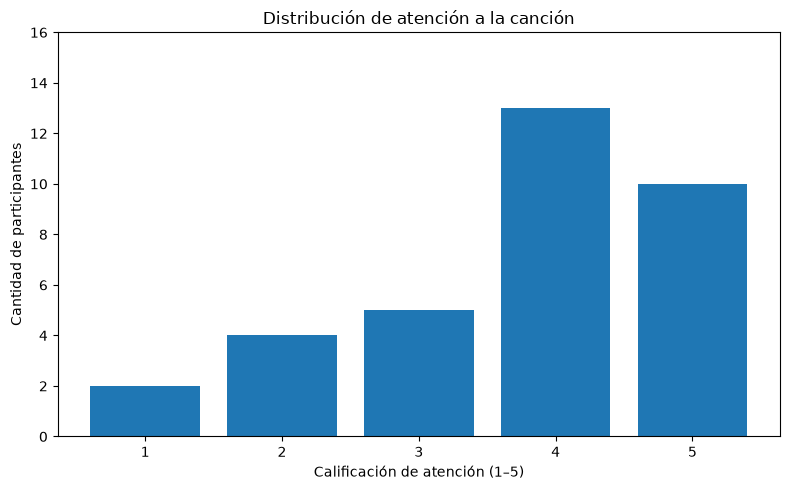

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    distribucion_atencion["Calificación"].astype(str),
    distribucion_atencion["Cantidad"]
)

plt.xlabel("Calificación de atención (1–5)")
plt.ylabel("Cantidad de participantes")
plt.title("Distribución de atención a la canción")

plt.ylim(0, distribucion_atencion["Cantidad"].max() + 3)

plt.tight_layout()
plt.show()

In [22]:
columna = "¿Cómo calificarías la diversión general de la interacción?"

diversion = pd.to_numeric(
    df_encuestas_dificultad[columna],
    errors="coerce"
)

# Conservar respuestas válidas
diversion = diversion[diversion.isin([1, 2, 3, 4, 5])]

# Distribución de respuestas
distribucion_diversion = (
    diversion.value_counts()
    .reindex(range(1, 6), fill_value=0)
    .sort_index()
    .rename_axis("Calificación")
    .reset_index(name="Cantidad")
)

distribucion_diversion["Porcentaje"] = (
    distribucion_diversion["Cantidad"] /
    distribucion_diversion["Cantidad"].sum() * 100
).round(2)

display(distribucion_diversion)

print(f"Total de respuestas: {len(diversion)}")
print(f"Promedio de diversión: {diversion.mean():.2f}")

,Calificación,Cantidad,Porcentaje
0,1,0,0.00
1,2,1,3.03
2,3,0,0.00
3,4,16,48.48
4,5,16,48.48


Total de respuestas: 33
Promedio de diversión: 4.42


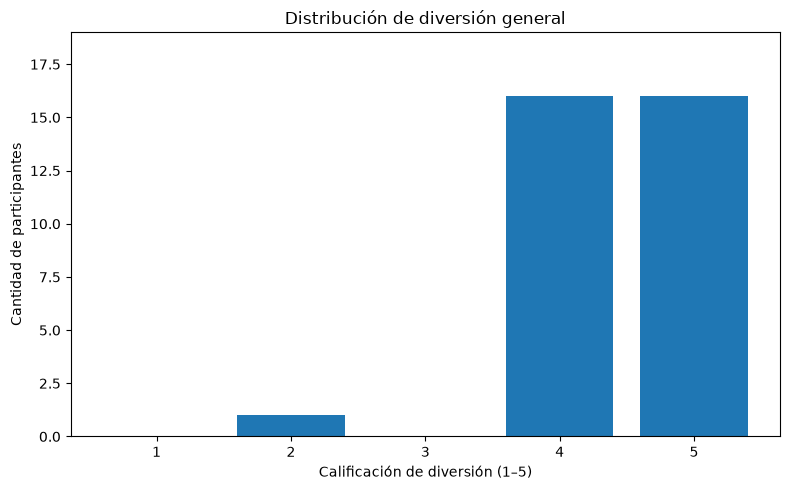

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    distribucion_diversion["Calificación"].astype(str),
    distribucion_diversion["Cantidad"]
)

plt.xlabel("Calificación de diversión (1–5)")
plt.ylabel("Cantidad de participantes")
plt.title("Distribución de diversión general")

plt.ylim(0, distribucion_diversion["Cantidad"].max() + 3)

plt.tight_layout()
plt.show()

In [24]:
columna = "¿Te sentiste abrumado durante la experiencia?"

# Orden de las respuestas
orden_agobio = [
    "Nada abrumado",
    "Ligeramente abrumado",
    "Moderadamente abrumado",
    "Muy abrumado"
]

agobio = (
    df_encuestas_dificultad[columna]
    .astype("string")
    .str.strip()
)

distribucion_agobio = (
    agobio.value_counts()
    .reindex(orden_agobio, fill_value=0)
    .rename_axis("Nivel de agobio")
    .reset_index(name="Cantidad")
)

distribucion_agobio["Porcentaje"] = (
    distribucion_agobio["Cantidad"] /
    distribucion_agobio["Cantidad"].sum() * 100
).round(2)

display(distribucion_agobio)

,Nivel de agobio,Cantidad,Porcentaje
0,Nada abrumado,11,32.35
1,Ligeramente abrumado,14,41.18
2,Moderadamente abrumado,8,23.53
3,Muy abrumado,1,2.94


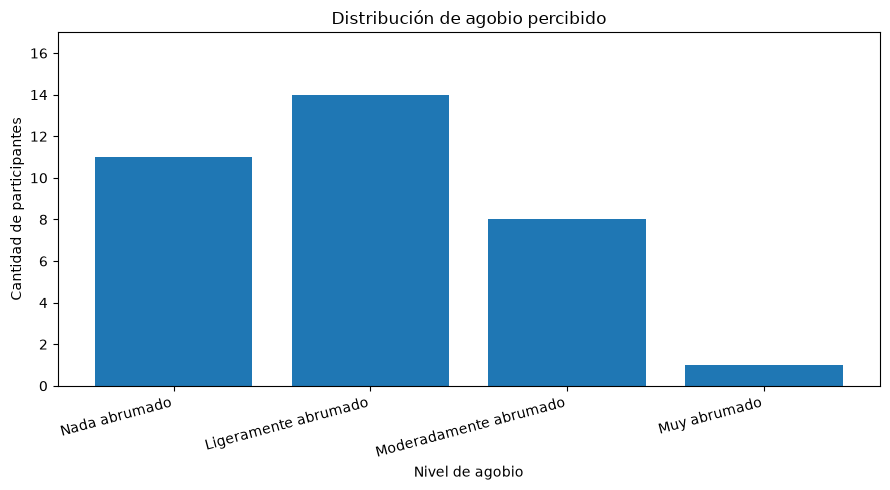

In [25]:
plt.figure(figsize=(9, 5))

plt.bar(
    distribucion_agobio["Nivel de agobio"],
    distribucion_agobio["Cantidad"]
)

plt.xlabel("Nivel de agobio")
plt.ylabel("Cantidad de participantes")
plt.title("Distribución de agobio percibido")

plt.xticks(rotation=15, ha="right")
plt.ylim(0, distribucion_agobio["Cantidad"].max() + 3)

plt.tight_layout()
plt.show()

In [26]:
columna = "¿Cómo calificarías tu desempeño general en los mini juegos?"

orden_desempeno = [
    "Bueno",
    "Intermedio",
    "Malo"
]

desempeno = (
    df_encuestas_dificultad[columna]
    .astype("string")
    .str.strip()
)

distribucion_desempeno = (
    desempeno.value_counts()
    .reindex(orden_desempeno, fill_value=0)
    .rename_axis("Desempeño")
    .reset_index(name="Cantidad")
)

distribucion_desempeno["Porcentaje"] = (
    distribucion_desempeno["Cantidad"] /
    distribucion_desempeno["Cantidad"].sum() * 100
).round(2)

display(distribucion_desempeno)

,Desempeño,Cantidad,Porcentaje
0,Bueno,13,38.24
1,Intermedio,16,47.06
2,Malo,5,14.71


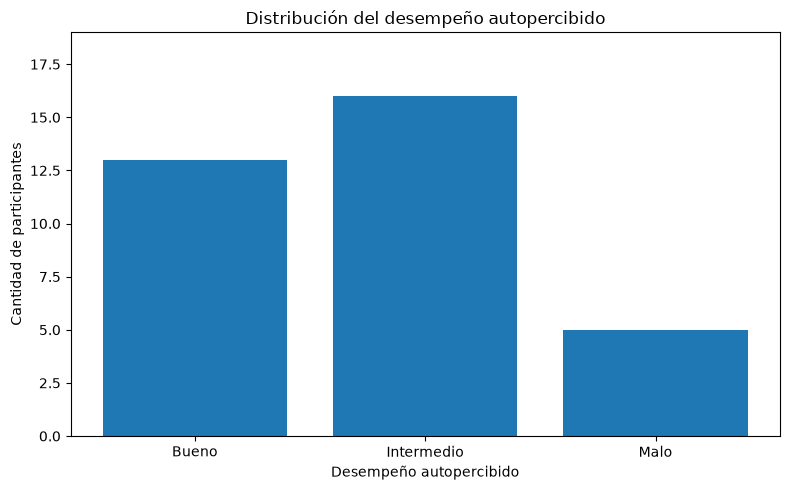

In [27]:
plt.figure(figsize=(8, 5))

plt.bar(
    distribucion_desempeno["Desempeño"],
    distribucion_desempeno["Cantidad"]
)

plt.xlabel("Desempeño autopercibido")
plt.ylabel("Cantidad de participantes")
plt.title("Distribución del desempeño autopercibido")

plt.ylim(0, distribucion_desempeno["Cantidad"].max() + 3)

plt.tight_layout()
plt.show()

In [28]:
import pandas as pd

columna = "¿Qué minijuego te frustró más?"

# Equivalencias entre la encuesta y el documento
nombres_minijuegos = {
    "Calabazas y Martillos": "Alex",
    "Pelea de Guitarras": "Joaquin",
    "Cortar comida": "Shipi",
    "Lavar al Perro": "Juan Andres",
    "Disparar a enemigos": "Danniel",
    "Cortar enemigos": "Jeremy"
}

# Limpiar las respuestas eliminando el número inicial
respuestas = (
    df_encuestas_dificultad[columna]
    .astype("string")
    .str.replace(r"^\s*\d+\s*-\s*", "", regex=True)
    .str.strip()
)

# Reemplazar los nombres por los del documento
respuestas = respuestas.map(nombres_minijuegos)

# Definir orden de minijuegos
orden = [
    "Alex",
    "Joaquin",
    "Shipi",
    "Juan Andres",
    "Danniel",
    "Jeremy"
]

# Contar respuestas
distribucion_frustracion = (
    respuestas.value_counts()
    .reindex(orden, fill_value=0)
    .rename_axis("Minijuego")
    .reset_index(name="Cantidad")
)

# Calcular porcentajes
distribucion_frustracion["Porcentaje"] = (
    distribucion_frustracion["Cantidad"] /
    distribucion_frustracion["Cantidad"].sum() * 100
).round(2)

display(distribucion_frustracion)

,Minijuego,Cantidad,Porcentaje
0,Alex,1,2.94
1,Joaquin,9,26.47
2,Shipi,4,11.76
3,Juan Andres,11,32.35
4,Danniel,4,11.76
5,Jeremy,5,14.71


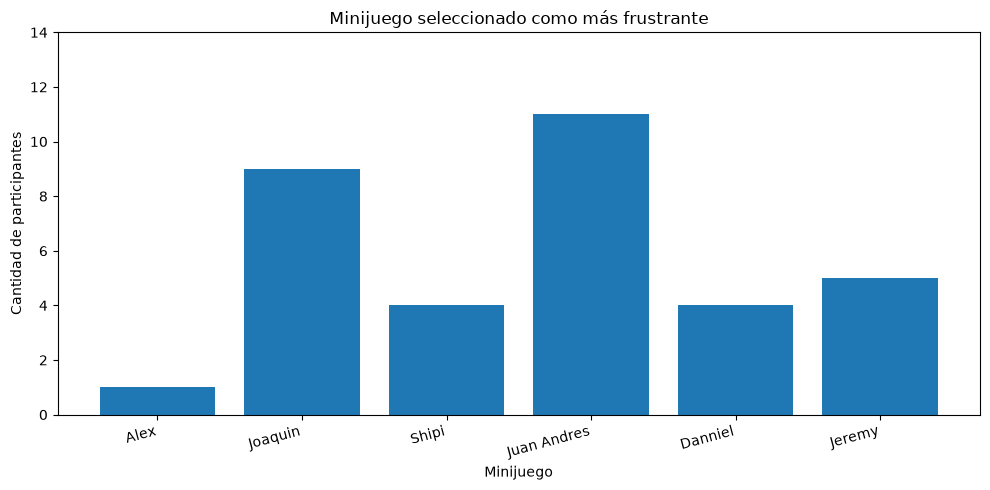

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    distribucion_frustracion["Minijuego"],
    distribucion_frustracion["Cantidad"]
)

plt.xlabel("Minijuego")
plt.ylabel("Cantidad de participantes")
plt.title("Minijuego seleccionado como más frustrante")

plt.xticks(rotation=15, ha="right")
plt.ylim(0, distribucion_frustracion["Cantidad"].max() + 3)

plt.tight_layout()
plt.show()

In [30]:
# Guardar los identificadores originales para referencia
if "ParticipanteOriginal" not in df_encuestas_dificultad.columns:
    df_encuestas_dificultad["ParticipanteOriginal"] = (
        df_encuestas_dificultad["Participante"].copy()
    )

# Diccionario de correcciones
correcciones_ids = {
    "B023": "P023",
    "P011": "P0011"
}

# Normalizar y corregir los identificadores
df_encuestas_dificultad["Participante"] = (
    df_encuestas_dificultad["Participante"]
    .astype("string")
    .str.strip()
    .str.upper()
    .replace(correcciones_ids)
)

# Comprobar las correcciones
display(
    df_encuestas_dificultad[
        df_encuestas_dificultad["ParticipanteOriginal"]
        .astype("string").str.upper().isin(correcciones_ids)
    ][["ParticipanteOriginal", "Participante"]]
)

,ParticipanteOriginal,Participante
9,P011,P0011
20,B023,P023


In [31]:
# Identificadores de las encuestas
ids_encuestas = set(
    df_encuestas_dificultad["Participante"].dropna()
)

# Identificadores de las métricas
ids_metricas = set(
    df_final["Participante"]
    .astype("string")
    .str.strip()
    .str.upper()
    .dropna()
)

# Participantes sin correspondencia
sin_metricas = ids_encuestas - ids_metricas
sin_encuesta = ids_metricas - ids_encuestas

print("Participantes en encuestas:", len(ids_encuestas))
print("Participantes en métricas:", len(ids_metricas))

print("\nEncuestas sin métricas:", sorted(sin_metricas))
print("Métricas sin encuesta:", sorted(sin_encuesta))

Participantes en encuestas: 34
Participantes en métricas: 34

Encuestas sin métricas: []
Métricas sin encuesta: []


In [32]:
import pandas as pd

# ---------------------------------------------
# 1. Calcular tasa de éxito por minijuego
# ---------------------------------------------

inter = df_final.copy()

inter["Participante"] = (
    inter["Participante"].astype("string").str.strip().str.upper()
)

inter["Minijuego"] = (
    inter["Minijuego"].astype("string").str.strip()
    .replace({"Juan Andres": "JuanAndres"})
)

inter["Resultado"] = (
    inter["Resultado"].astype("string").str.strip().str.title()
)

# Solo resultados válidos
inter = inter[
    inter["Resultado"].isin(["Success", "Failed", "Missed"])
]

tasas = (
    inter.groupby(["Participante", "Minijuego"], as_index=False)
    .agg(
        Interacciones=("Resultado", "size"),
        Aciertos=("Resultado", lambda x: (x == "Success").sum())
    )
)

tasas["TasaExito"] = tasas["Aciertos"] / tasas["Interacciones"]

# Identificar el mínimo de cada participante
minimo = tasas.groupby("Participante")["TasaExito"].transform("min")

peores = tasas[
    (tasas["TasaExito"] - minimo).abs() < 1e-12
].copy()

# Conservar todos los minijuegos empatados en el mínimo
peores_por_participante = (
    peores.groupby("Participante", as_index=False)
    .agg(
        MinijuegosMenorExito=(
            "Minijuego", lambda x: " | ".join(sorted(x))
        ),
        CantidadMinimos=("Minijuego", "size"),
        TasaMinima=("TasaExito", "first")
    )
)

# ---------------------------------------------
# 2. Obtener el minijuego más frustrante
# ---------------------------------------------

nombres_encuesta = {
    "Calabazas y Martillos": "Alex",
    "Pelea de Guitarras": "Joaquin",
    "Cortar comida": "Shipi",
    "Lavar al Perro": "JuanAndres",
    "Disparar a enemigos": "Danniel",
    "Cortar enemigos": "Jeremy"
}

mapa = {k.casefold(): v for k, v in nombres_encuesta.items()}

columna = "¿Qué minijuego te frustró más?"

enc = df_encuestas_dificultad[
    ["Participante", columna]
].copy()

enc["Participante"] = (
    enc["Participante"].astype("string").str.strip().str.upper()
)

# Eliminar número inicial: "4 - Cortar comida" -> "Cortar comida"
respuesta = (
    enc[columna]
    .astype("string")
    .str.replace(r"^\s*\d+\s*-\s*", "", regex=True)
    .str.strip()
    .str.casefold()
)

enc["MasFrustrante"] = respuesta.map(mapa)

# Evitar cruces ambiguos
if enc["Participante"].duplicated().any():
    raise ValueError("Hay participantes repetidos en la encuesta.")

# ---------------------------------------------
# 3. Cruzar encuesta y métricas
# ---------------------------------------------

comparacion = enc[
    ["Participante", "MasFrustrante"]
].dropna().merge(
    peores_por_participante,
    on="Participante",
    how="inner",
    validate="one_to_one"
)

# Coincide si el seleccionado está entre los de menor éxito
comparacion["Coincide"] = comparacion.apply(
    lambda fila: fila["MasFrustrante"]
    in fila["MinijuegosMenorExito"].split(" | "),
    axis=1
)

# Separar los empates para la gráfica
comparacion["MenorExitoGrafica"] = comparacion.apply(
    lambda fila: (
        fila["MinijuegosMenorExito"]
        if fila["CantidadMinimos"] == 1
        else "Empate"
    ),
    axis=1
)

comparacion["TasaMinima_%"] = (
    comparacion["TasaMinima"] * 100
).round(2)

comparacion = comparacion.sort_values(
    "Participante"
).reset_index(drop=True)

# ---------------------------------------------
# 4. Mostrar resultados
# ---------------------------------------------

display(comparacion[
    [
        "Participante",
        "MasFrustrante",
        "MinijuegosMenorExito",
        "TasaMinima_%",
        "Coincide"
    ]
])

coincidencias = comparacion["Coincide"].sum()
total = len(comparacion)

print(f"Participantes comparados: {total}")

if total:
    print(f"Coincidencias: {coincidencias}")
    print(f"No coincidencias: {total - coincidencias}")
    print(f"Porcentaje de coincidencia: {coincidencias / total * 100:.2f}%")

print(
    "Participantes de encuesta sin métricas:",
    sorted(set(enc["Participante"]) - set(tasas["Participante"]))
)

,Participante,MasFrustrante,MinijuegosMenorExito,TasaMinima_%,Coincide
0,P001,Shipi,Shipi,12.50,True
1,P0011,Joaquin,JuanAndres,17.65,False
2,P002,Joaquin,Joaquin,24.14,True
3,P003,JuanAndres,Shipi,14.29,False
4,P004,Shipi,Shipi,43.75,True
5,P005,Danniel,JuanAndres,33.33,False
6,P006,Alex,Shipi,52.38,False
7,P007,Shipi,JuanAndres,11.11,False
8,P008,Joaquin,Jeremy,37.50,False
9,P010,Joaquin,JuanAndres,25.00,False


Participantes comparados: 34
Coincidencias: 13
No coincidencias: 21
Porcentaje de coincidencia: 38.24%
Participantes de encuesta sin métricas: []


In [33]:
# Separar los minijuegos empatados en filas individuales
comparacion_expandida = comparacion.copy()

comparacion_expandida["MenorExito"] = (
    comparacion_expandida["MinijuegosMenorExito"]
    .str.split(" | ", regex=False)
)

comparacion_expandida = (
    comparacion_expandida
    .explode("MenorExito")
    .reset_index(drop=True)
)

# Cada comparación se clasifica individualmente
comparacion_expandida["Coincide"] = (
    comparacion_expandida["MasFrustrante"] ==
    comparacion_expandida["MenorExito"]
)

# Mostrar comparación completa
display(comparacion_expandida[
    [
        "Participante",
        "MasFrustrante",
        "MenorExito",
        "TasaMinima_%",
        "Coincide"
    ]
])

# Estadísticas
coincidencias = comparacion_expandida["Coincide"].sum()
no_coincidencias = (~comparacion_expandida["Coincide"]).sum()

total_comparaciones = len(comparacion_expandida)
total_participantes = comparacion_expandida["Participante"].nunique()

print(f"Participantes analizados: {total_participantes}")
print(f"Comparaciones realizadas: {total_comparaciones}")
print(f"Coincidencias: {coincidencias}")
print(f"No coincidencias: {no_coincidencias}")

print(
    f"Porcentaje de coincidencias: "
    f"{coincidencias / total_comparaciones * 100:.2f}%"
)

,Participante,MasFrustrante,MenorExito,TasaMinima_%,Coincide
0,P001,Shipi,Shipi,12.50,True
1,P0011,Joaquin,JuanAndres,17.65,False
2,P002,Joaquin,Joaquin,24.14,True
3,P003,JuanAndres,Shipi,14.29,False
4,P004,Shipi,Shipi,43.75,True
5,P005,Danniel,JuanAndres,33.33,False
6,P006,Alex,Shipi,52.38,False
7,P007,Shipi,JuanAndres,11.11,False
8,P008,Joaquin,Jeremy,37.50,False
9,P010,Joaquin,JuanAndres,25.00,False


Participantes analizados: 34
Comparaciones realizadas: 35
Coincidencias: 13
No coincidencias: 22
Porcentaje de coincidencias: 37.14%


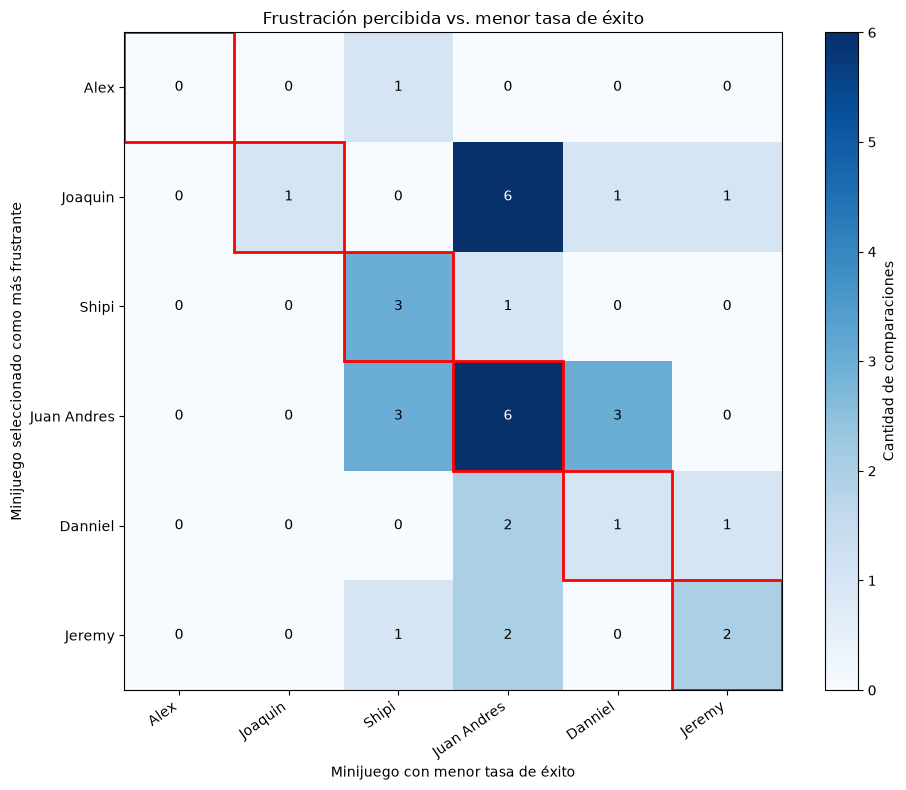

In [34]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# Orden de los minijuegos
orden = [
    "Alex",
    "Joaquin",
    "Shipi",
    "JuanAndres",
    "Danniel",
    "Jeremy"
]

etiquetas = [
    "Alex",
    "Joaquin",
    "Shipi",
    "Juan Andres",
    "Danniel",
    "Jeremy"
]

# Construir matriz, incluyendo cada empate por separado
matriz = pd.crosstab(
    comparacion_expandida["MasFrustrante"],
    comparacion_expandida["MenorExito"]
).reindex(
    index=orden,
    columns=orden,
    fill_value=0
)

fig, ax = plt.subplots(figsize=(10, 8))

imagen = ax.imshow(
    matriz.values,
    cmap="Blues",
    aspect="equal"
)

# Etiquetas
ax.set_xticks(range(len(orden)))
ax.set_xticklabels(etiquetas, rotation=35, ha="right")

ax.set_yticks(range(len(orden)))
ax.set_yticklabels(etiquetas)

ax.set_xlabel("Minijuego con menor tasa de éxito")
ax.set_ylabel("Minijuego seleccionado como más frustrante")

ax.set_title(
    "Frustración percibida vs. menor tasa de éxito"
)

# Mostrar cantidades
for i in range(len(orden)):
    for j in range(len(orden)):

        valor = matriz.iloc[i, j]

        ax.text(
            j, i, str(valor),
            ha="center",
            va="center",
            color="white" if valor > matriz.values.max() / 2 else "black"
        )

# Resaltar diagonal: coincidencias
for i in range(len(orden)):
    ax.add_patch(
        Rectangle(
            (i - 0.5, i - 0.5),
            1, 1,
            fill=False,
            edgecolor="red",
            linewidth=2
        )
    )

fig.colorbar(
    imagen,
    ax=ax,
    label="Cantidad de comparaciones"
)

plt.tight_layout()
plt.show()

In [35]:
import pandas as pd

# ---------------------------------------------
# 1. Obtener el agobio reportado en la encuesta
# ---------------------------------------------

columna = "¿Te sentiste abrumado durante la experiencia?"

df_agobio = df_encuestas_dificultad[
    ["Participante", columna]
].copy()

df_agobio = df_agobio.rename(
    columns={columna: "NivelAgobio"}
)

# Normalizar los identificadores
df_agobio["Participante"] = (
    df_agobio["Participante"]
    .astype("string")
    .str.strip()
    .str.upper()
    .replace({
        "B023": "P023",
        "P011": "P0011"
    })
)

df_agobio["NivelAgobio"] = (
    df_agobio["NivelAgobio"]
    .astype("string")
    .str.strip()
)

# ---------------------------------------------
# 2. Contar eventos Overloaded por participante
# ---------------------------------------------

eventos = df_eventos.copy()

eventos["Participante"] = (
    eventos["Participante"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Contar eventos Overloaded
overloaded = (
    eventos[
        (eventos["Categoria"] == "PlayerState") &
        (eventos["EstadoJugador"] == "Overloaded")
    ]
    .groupby("Participante")
    .size()
    .rename("Overloaded")
)

# Contar todas las interacciones
interacciones = (
    eventos[eventos["Categoria"] == "Interaction"]
    .groupby("Participante")
    .size()
    .rename("Interacciones")
)

# Unir los conteos
metricas = pd.DataFrame({
    "Participante": eventos["Participante"].dropna().unique()
})

metricas = metricas.merge(
    overloaded, on="Participante", how="left"
).merge(
    interacciones, on="Participante", how="left"
)

metricas[["Overloaded", "Interacciones"]] = (
    metricas[["Overloaded", "Interacciones"]]
    .fillna(0)
    .astype(int)
)

# Frecuencia por cada 100 interacciones
metricas["FrecuenciaOverloaded"] = (
    metricas["Overloaded"] /
    metricas["Interacciones"].replace(0, float("nan")) * 100
)

# ---------------------------------------------
# 3. Cruzar encuesta con métricas
# ---------------------------------------------

comparacion_agobio = df_agobio.merge(
    metricas,
    on="Participante",
    how="inner",
    validate="one_to_one"
)

comparacion_agobio["FrecuenciaOverloaded"] = (
    comparacion_agobio["FrecuenciaOverloaded"].round(2)
)

comparacion_agobio = comparacion_agobio.sort_values(
    "Participante"
)

display(comparacion_agobio)

,Participante,NivelAgobio,Overloaded,Interacciones,FrecuenciaOverloaded
0,P001,Ligeramente abrumado,7,132,5.30
9,P0011,Ligeramente abrumado,7,138,5.07
1,P002,Ligeramente abrumado,7,165,4.24
3,P003,Ligeramente abrumado,10,169,5.92
2,P004,Moderadamente abrumado,5,206,2.43
6,P005,Nada abrumado,4,154,2.60
5,P006,Ligeramente abrumado,4,181,2.21
7,P007,Ligeramente abrumado,6,109,5.50
4,P008,Ligeramente abrumado,7,128,5.47
8,P010,Moderadamente abrumado,5,115,4.35


In [36]:
# Orden de los niveles
orden_agobio = [
    "Nada abrumado",
    "Ligeramente abrumado",
    "Moderadamente abrumado",
    "Muy abrumado"
]

# Agrupar por nivel de agobio
resumen_agobio = (
    comparacion_agobio
    .groupby("NivelAgobio")
    .agg(
        Participantes=("Participante", "count"),
        PromedioOverloaded=("Overloaded", "mean"),
        MedianaOverloaded=("Overloaded", "median"),
        PromedioFrecuencia=("FrecuenciaOverloaded", "mean")
    )
    .reindex(orden_agobio)
    .reset_index()
)

# Redondear promedios
resumen_agobio[
    ["PromedioOverloaded", "MedianaOverloaded", "PromedioFrecuencia"]
] = resumen_agobio[
    ["PromedioOverloaded", "MedianaOverloaded", "PromedioFrecuencia"]
].round(2)

display(resumen_agobio)

,NivelAgobio,Participantes,PromedioOverloaded,MedianaOverloaded,PromedioFrecuencia
0,Nada abrumado,11,6.09,6.0,4.19
1,Ligeramente abrumado,14,6.36,7.0,4.71
2,Moderadamente abrumado,8,6.25,6.0,4.14
3,Muy abrumado,1,6.00,6.0,4.96


<>:11: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:12: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:70: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:11: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:12: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:70: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
C:\Users\Lenovo _ LeGion\AppData\Local\Temp\ipykernel_35560\2896155383.py:11

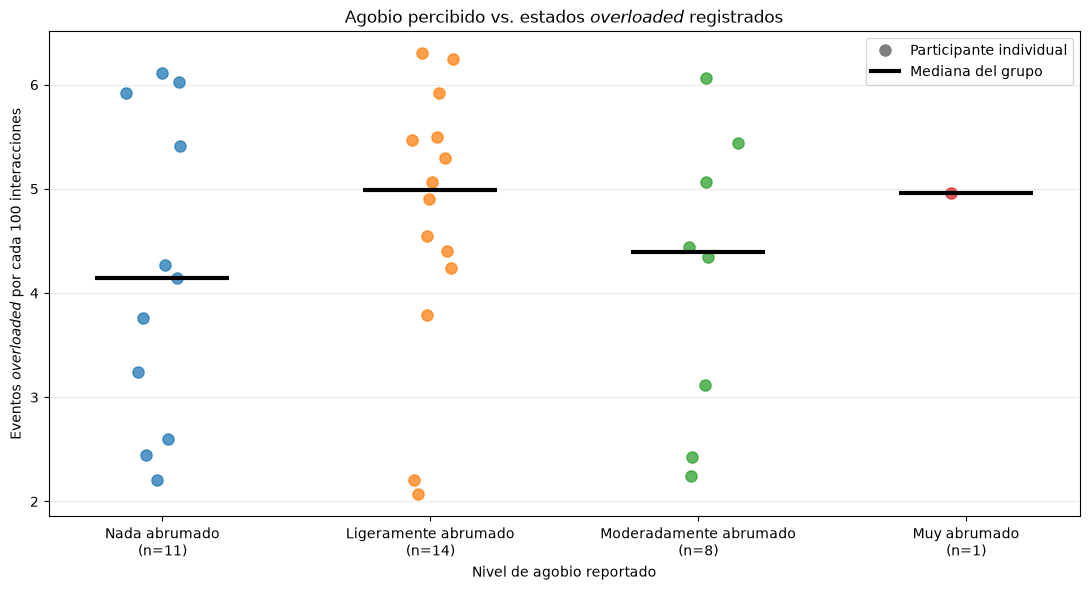

In [37]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

# Elegir variable
# "Overloaded" = cantidad total
# "FrecuenciaOverloaded" = eventos por cada 100 interacciones
variable = "FrecuenciaOverloaded"

etiquetas_variables = {
    "Overloaded": "Cantidad de eventos $\mathit{overloaded}$",
    "FrecuenciaOverloaded": "Eventos $\mathit{overloaded}$ por cada 100 interacciones"
}

orden_agobio = [
    "Nada abrumado",
    "Ligeramente abrumado",
    "Moderadamente abrumado",
    "Muy abrumado"
]

fig, ax = plt.subplots(figsize=(11, 6))

rng = np.random.default_rng(42)
etiquetas_x = []

for i, nivel in enumerate(orden_agobio):

    datos = comparacion_agobio.loc[
        comparacion_agobio["NivelAgobio"] == nivel,
        variable
    ].dropna()

    # Agregar cantidad de participantes a la etiqueta
    n = len(datos)
    etiquetas_x.append(f"{nivel}\n(n={n})")

    # Dibujar puntos individuales con ligera dispersión horizontal
    x = rng.normal(i, 0.07, size=n)

    ax.scatter(
        x,
        datos,
        s=65,
        alpha=0.75,
        zorder=3
    )

    # Dibujar la mediana de cada categoría
    if n > 0:
        mediana = datos.median()

        ax.hlines(
            mediana,
            i - 0.25,
            i + 0.25,
            linewidth=3,
            color="black",
            zorder=4
        )

# Etiquetas
ax.set_xticks(range(len(orden_agobio)))
ax.set_xticklabels(etiquetas_x)

ax.set_xlabel("Nivel de agobio reportado")
ax.set_ylabel(etiquetas_variables[variable])

ax.set_title(
    "Agobio percibido vs. estados $\mathit{overloaded}$ registrados"
)

ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

# Leyenda personalizada
leyenda = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markersize=8,
        color="gray",
        label="Participante individual"
    ),
    Line2D(
        [0], [0],
        linestyle="-",
        linewidth=3,
        color="black",
        label="Mediana del grupo"
    )
]

ax.legend(
    handles=leyenda,
    loc="upper right",
    frameon=True
)

plt.tight_layout()
plt.show()

In [38]:
import pandas as pd

# ---------------------------------------------
# 1. Obtener el desempeño autopercibido
# ---------------------------------------------

columna = "¿Cómo calificarías tu desempeño general en los mini juegos?"

df_desempeno = df_encuestas_dificultad[
    ["Participante", columna]
].copy()

df_desempeno = df_desempeno.rename(
    columns={columna: "DesempenoPercibido"}
)

# Normalizar identificadores
df_desempeno["Participante"] = (
    df_desempeno["Participante"]
    .astype("string")
    .str.strip()
    .str.upper()
    .replace({
        "B023": "P023",
        "P011": "P0011"
    })
)

df_desempeno["DesempenoPercibido"] = (
    df_desempeno["DesempenoPercibido"]
    .astype("string")
    .str.strip()
    .str.title()
)

# Conservar categorías válidas
orden_desempeno = ["Malo", "Intermedio", "Bueno"]

df_desempeno = df_desempeno[
    df_desempeno["DesempenoPercibido"].isin(orden_desempeno)
]

# ---------------------------------------------
# 2. Calcular tasa de éxito total
# ---------------------------------------------

interacciones = df_final.copy()

interacciones["Participante"] = (
    interacciones["Participante"]
    .astype("string")
    .str.strip()
    .str.upper()
)

interacciones["Resultado"] = (
    interacciones["Resultado"]
    .astype("string")
    .str.strip()
    .str.title()
)

# Considerar únicamente resultados válidos
interacciones = interacciones[
    interacciones["Resultado"].isin(
        ["Success", "Failed", "Missed"]
    )
]

# Calcular aciertos e interacciones por participante
metricas_exito = (
    interacciones
    .groupby("Participante", as_index=False)
    .agg(
        TotalInteracciones=("Resultado", "size"),
        Aciertos=("Resultado", lambda x: (x == "Success").sum())
    )
)

# Calcular porcentaje
metricas_exito["TasaExito"] = (
    metricas_exito["Aciertos"] /
    metricas_exito["TotalInteracciones"] * 100
)

# ---------------------------------------------
# 3. Cruzar encuesta con métricas
# ---------------------------------------------

comparacion_desempeno = df_desempeno.merge(
    metricas_exito,
    on="Participante",
    how="inner",
    validate="one_to_one"
)

comparacion_desempeno["TasaExito"] = (
    comparacion_desempeno["TasaExito"].round(2)
)

comparacion_desempeno = comparacion_desempeno.sort_values(
    "Participante"
)

display(comparacion_desempeno)

print(f"Participantes analizados: {len(comparacion_desempeno)}")

,Participante,DesempenoPercibido,TotalInteracciones,Aciertos,TasaExito
0,P001,Malo,132,62,46.97
9,P0011,Malo,138,74,53.62
1,P002,Intermedio,165,103,62.42
3,P003,Intermedio,169,84,49.70
2,P004,Intermedio,206,144,69.90
6,P005,Bueno,154,98,63.64
5,P006,Malo,181,117,64.64
7,P007,Bueno,109,44,40.37
4,P008,Bueno,128,70,54.69
8,P010,Bueno,115,68,59.13


Participantes analizados: 34


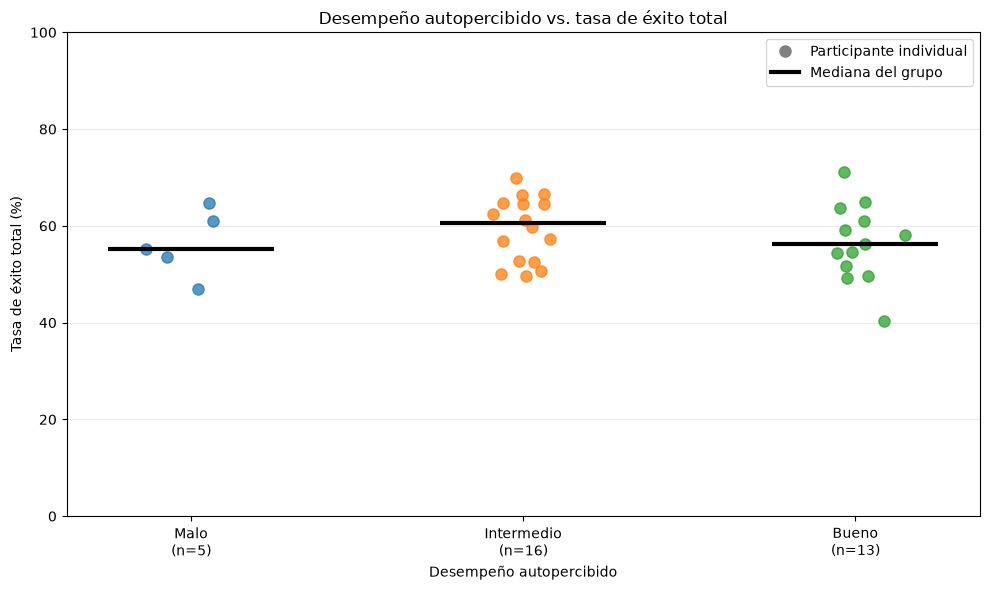

In [39]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(10, 6))

rng = np.random.default_rng(42)
etiquetas_x = []

for i, nivel in enumerate(orden_desempeno):

    datos = comparacion_desempeno.loc[
        comparacion_desempeno["DesempenoPercibido"] == nivel,
        "TasaExito"
    ].dropna()

    # Cantidad de participantes
    n = len(datos)
    etiquetas_x.append(f"{nivel}\n(n={n})")

    # Dispersión horizontal de puntos
    x = rng.normal(i, 0.07, size=n)

    ax.scatter(
        x,
        datos,
        s=65,
        alpha=0.75,
        zorder=3
    )

    # Mediana por categoría
    if n > 0:
        mediana = datos.median()

        ax.hlines(
            mediana,
            i - 0.25,
            i + 0.25,
            linewidth=3,
            color="black",
            zorder=4
        )

# Etiquetas
ax.set_xticks(range(len(orden_desempeno)))
ax.set_xticklabels(etiquetas_x)

ax.set_xlabel("Desempeño autopercibido")
ax.set_ylabel("Tasa de éxito total (%)")

ax.set_title(
    "Desempeño autopercibido vs. tasa de éxito total"
)

ax.set_ylim(0, 100)

ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

# Leyenda
leyenda = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markersize=8,
        color="gray",
        label="Participante individual"
    ),
    Line2D(
        [0], [0],
        linestyle="-",
        linewidth=3,
        color="black",
        label="Mediana del grupo"
    )
]

ax.legend(
    handles=leyenda,
    loc="upper right"
)

plt.tight_layout()
plt.show()

In [40]:
import pandas as pd

# ---------------------------------------------
# 1. Obtener atención reportada en la encuesta
# ---------------------------------------------

columna = "¿Pudiste ponerle atención a la canción?"

df_atencion = df_encuestas_dificultad[
    ["Participante", columna]
].copy()

df_atencion = df_atencion.rename(
    columns={columna: "Atencion"}
)

# Normalizar identificadores
df_atencion["Participante"] = (
    df_atencion["Participante"]
    .astype("string")
    .str.strip()
    .str.upper()
    .replace({
        "B023": "P023",
        "P011": "P0011"
    })
)

# Convertir respuestas a números
df_atencion["Atencion"] = pd.to_numeric(
    df_atencion["Atencion"],
    errors="coerce"
)

# Conservar escala 1–5
df_atencion = df_atencion[
    df_atencion["Atencion"].isin([1, 2, 3, 4, 5])
]

# ---------------------------------------------
# 2. Contar eventos Overloaded
# ---------------------------------------------

eventos = df_eventos.copy()

eventos["Participante"] = (
    eventos["Participante"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Obtener todos los participantes con eventos
participantes = eventos[
    ["Participante"]
].dropna().drop_duplicates()

# Contar estados Overloaded
conteo_overloaded = (
    eventos[
        (eventos["Categoria"] == "PlayerState") &
        (eventos["EstadoJugador"] == "Overloaded")
    ]
    .groupby("Participante")
    .size()
    .reset_index(name="Overloaded")
)

# Incluir participantes con cero estados Overloaded
conteo_overloaded = participantes.merge(
    conteo_overloaded,
    on="Participante",
    how="left"
)

conteo_overloaded["Overloaded"] = (
    conteo_overloaded["Overloaded"].fillna(0).astype(int)
)

# ---------------------------------------------
# 3. Cruzar encuesta y métricas
# ---------------------------------------------

comparacion_atencion = df_atencion.merge(
    conteo_overloaded,
    on="Participante",
    how="inner",
    validate="one_to_one"
)

comparacion_atencion = comparacion_atencion.sort_values(
    "Participante"
).reset_index(drop=True)

display(comparacion_atencion)

print(f"Participantes analizados: {len(comparacion_atencion)}")

,Participante,Atencion,Overloaded
0,P001,2,7
1,P0011,3,7
2,P002,3,7
3,P003,4,10
4,P004,5,5
5,P005,5,4
6,P006,4,4
7,P007,5,6
8,P008,2,7
9,P010,4,5


Participantes analizados: 34


<>:53: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:53: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
C:\Users\Lenovo _ LeGion\AppData\Local\Temp\ipykernel_35560\3653342951.py:53: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  ax.set_ylabel("Cantidad de eventos $\mathit{overloaded}$")


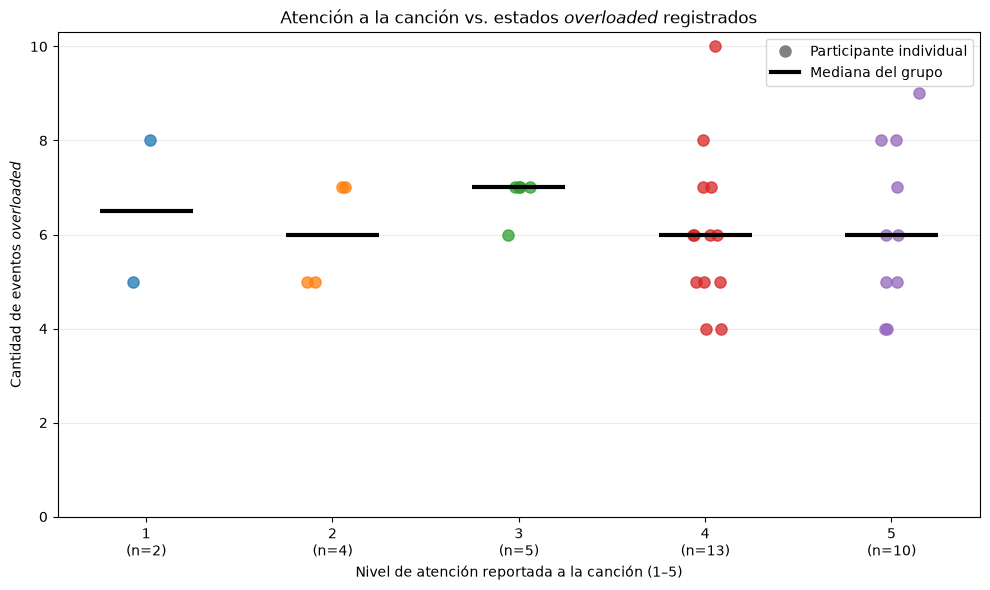

In [41]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

orden_atencion = [1, 2, 3, 4, 5]

fig, ax = plt.subplots(figsize=(10, 6))

rng = np.random.default_rng(42)
etiquetas_x = []

for i, nivel in enumerate(orden_atencion):

    datos = comparacion_atencion.loc[
        comparacion_atencion["Atencion"] == nivel,
        "Overloaded"
    ].dropna()

    # Cantidad de participantes
    n = len(datos)
    etiquetas_x.append(f"{nivel}\n(n={n})")

    # Dispersión horizontal para evitar superposición
    x = rng.normal(i, 0.07, size=n)

    # Puntos individuales
    ax.scatter(
        x,
        datos,
        s=65,
        alpha=0.75,
        zorder=3
    )

    # Mediana por categoría
    if n > 0:
        mediana = datos.median()

        ax.hlines(
            mediana,
            i - 0.25,
            i + 0.25,
            linewidth=3,
            color="black",
            zorder=4
        )

# Etiquetas
ax.set_xticks(range(len(orden_atencion)))
ax.set_xticklabels(etiquetas_x)

ax.set_xlabel("Nivel de atención reportada a la canción (1–5)")
ax.set_ylabel("Cantidad de eventos $\mathit{overloaded}$")

ax.set_title(
    r"Atención a la canción vs. estados $\mathit{overloaded}$ registrados"
)

ax.set_ylim(bottom=0)

ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

# Leyenda personalizada
leyenda = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markersize=8,
        color="gray",
        label="Participante individual"
    ),
    Line2D(
        [0], [0],
        linestyle="-",
        linewidth=3,
        color="black",
        label="Mediana del grupo"
    )
]

ax.legend(
    handles=leyenda,
    loc="upper right",
    frameon=True
)

plt.tight_layout()
plt.show()

In [42]:
import pandas as pd

# ---------------------------------------------
# 1. Obtener atención reportada
# ---------------------------------------------

columna = "¿Pudiste ponerle atención a la canción?"

df_atencion = df_encuestas_dificultad[
    ["Participante", columna]
].copy()

df_atencion = df_atencion.rename(
    columns={columna: "Atencion"}
)

# Normalizar identificadores
df_atencion["Participante"] = (
    df_atencion["Participante"]
    .astype("string")
    .str.strip()
    .str.upper()
    .replace({
        "B023": "P023",
        "P011": "P0011"
    })
)

# Convertir respuestas a números
df_atencion["Atencion"] = pd.to_numeric(
    df_atencion["Atencion"],
    errors="coerce"
)

df_atencion = df_atencion[
    df_atencion["Atencion"].isin([1, 2, 3, 4, 5])
]

# ---------------------------------------------
# 2. Contar reducciones de dificultad
# ---------------------------------------------

eventos = df_eventos.copy()

eventos["Participante"] = (
    eventos["Participante"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Filtrar cambios de dificultad
cambios = eventos[
    eventos["Categoria"] == "DifficultyChanged"
].copy()

# Normalizar las transiciones
cambios["CambioDificultad"] = (
    cambios["CambioDificultad"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s*->\s*", " -> ", regex=True)
)

# Definir reducciones
reducciones = [
    "Hard -> Normal",
    "Normal -> Easy"
]

# Contar únicamente las reducciones
conteo_reducciones = (
    cambios[
        cambios["CambioDificultad"].isin(reducciones)
    ]
    .groupby("Participante")
    .size()
    .reset_index(name="Reducciones")
)

# Incluir participantes con cero reducciones
participantes = eventos[
    ["Participante"]
].dropna().drop_duplicates()

conteo_reducciones = participantes.merge(
    conteo_reducciones,
    on="Participante",
    how="left"
)

conteo_reducciones["Reducciones"] = (
    conteo_reducciones["Reducciones"]
    .fillna(0)
    .astype(int)
)

# ---------------------------------------------
# 3. Cruzar encuesta y métricas
# ---------------------------------------------

comparacion_reducciones = df_atencion.merge(
    conteo_reducciones,
    on="Participante",
    how="inner",
    validate="one_to_one"
)

comparacion_reducciones = (
    comparacion_reducciones
    .sort_values("Participante")
    .reset_index(drop=True)
)

display(comparacion_reducciones)

print(
    f"Participantes analizados: "
    f"{len(comparacion_reducciones)}"
)

,Participante,Atencion,Reducciones
0,P001,2,4
1,P0011,3,4
2,P002,3,6
3,P003,4,5
4,P004,5,4
5,P005,5,3
6,P006,4,4
7,P007,5,2
8,P008,2,2
9,P010,4,3


Participantes analizados: 34


In [43]:
orden_atencion = [1, 2, 3, 4, 5]

resumen_reducciones = (
    comparacion_reducciones
    .groupby("Atencion")
    .agg(
        Participantes=("Participante", "count"),
        PromedioReducciones=("Reducciones", "mean"),
        MedianaReducciones=("Reducciones", "median"),
        MinimoReducciones=("Reducciones", "min"),
        MaximoReducciones=("Reducciones", "max")
    )
    .reindex(orden_atencion)
    .reset_index()
)

# Redondear promedios
resumen_reducciones[
    ["PromedioReducciones", "MedianaReducciones"]
] = resumen_reducciones[
    ["PromedioReducciones", "MedianaReducciones"]
].round(2)

display(resumen_reducciones)

,Atencion,Participantes,PromedioReducciones,MedianaReducciones,MinimoReducciones,MaximoReducciones
0,1,2,5.00,5.0,4,6
1,2,4,3.00,3.0,2,4
2,3,5,4.60,5.0,2,6
3,4,13,3.23,3.0,2,6
4,5,10,3.30,3.0,2,6


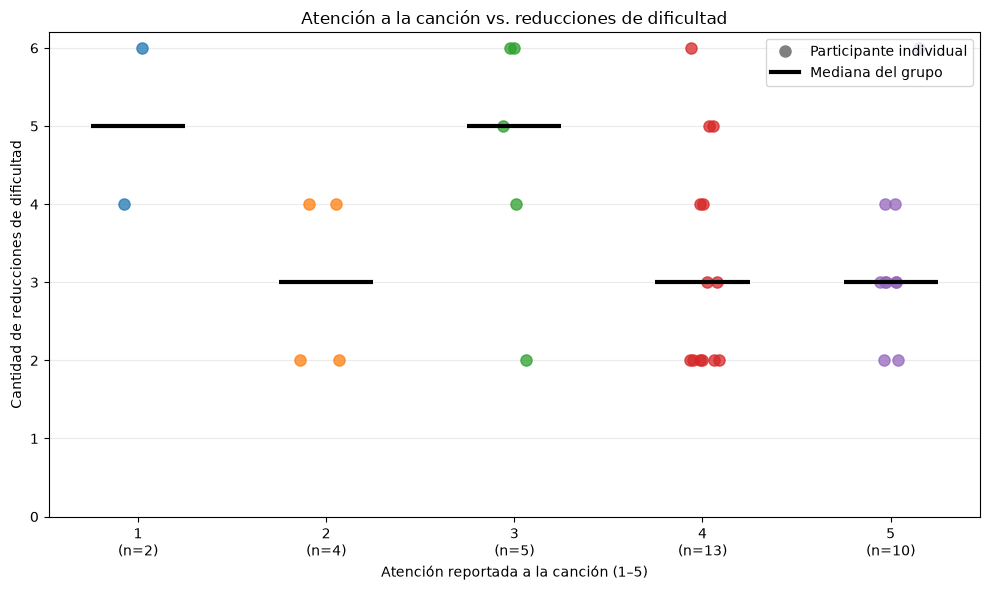

In [44]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

orden_atencion = [1, 2, 3, 4, 5]

fig, ax = plt.subplots(figsize=(10, 6))

rng = np.random.default_rng(42)
etiquetas_x = []

for i, nivel in enumerate(orden_atencion):

    datos = comparacion_reducciones.loc[
        comparacion_reducciones["Atencion"] == nivel,
        "Reducciones"
    ].dropna()

    # Cantidad de participantes
    n = len(datos)
    etiquetas_x.append(f"{nivel}\n(n={n})")

    # Dispersión horizontal
    x = rng.normal(i, 0.07, size=n)

    # Puntos individuales
    ax.scatter(
        x,
        datos,
        s=65,
        alpha=0.75,
        zorder=3
    )

    # Mediana del grupo
    if n > 0:
        mediana = datos.median()

        ax.hlines(
            mediana,
            i - 0.25,
            i + 0.25,
            linewidth=3,
            color="black",
            zorder=4
        )

# Etiquetas
ax.set_xticks(range(len(orden_atencion)))
ax.set_xticklabels(etiquetas_x)

ax.set_xlabel("Atención reportada a la canción (1–5)")
ax.set_ylabel("Cantidad de reducciones de dificultad")

ax.set_title(
    "Atención a la canción vs. reducciones de dificultad"
)

ax.set_ylim(bottom=0)

ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

# Leyenda
leyenda = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markersize=8,
        color="gray",
        label="Participante individual"
    ),
    Line2D(
        [0], [0],
        linestyle="-",
        linewidth=3,
        color="black",
        label="Mediana del grupo"
    )
]

ax.legend(
    handles=leyenda,
    loc="upper right",
    frameon=True
)

plt.tight_layout()
plt.show()

In [45]:
import pandas as pd

# Número de interacciones antes y después
N = 5

# Jerarquía de dificultades
NIVELES = {"Easy": 1, "Normal": 2, "Hard": 3}

eventos = df_eventos.copy()

# Normalizar datos
eventos["Participante"] = (
    eventos["Participante"].astype("string").str.strip().str.upper()
)

eventos["ArchivoOrigen"] = (
    eventos["ArchivoOrigen"].astype("string").str.strip()
)

eventos["IdEvento"] = pd.to_numeric(
    eventos["IdEvento"], errors="raise"
)

for columna in [
    "Categoria", "Minijuego", "Dificultad",
    "Resultado", "CambioDificultad"
]:
    eventos[columna] = eventos[columna].astype("string").str.strip()

eventos["CambioDificultad"] = (
    eventos["CambioDificultad"]
    .str.replace(r"\s*->\s*", " -> ", regex=True)
)

eventos.loc[eventos["Minijuego"] == "", "Minijuego"] = pd.NA

# Mantener orden cronológico original
eventos = eventos.sort_values(
    ["Participante", "ArchivoOrigen", "IdEvento"],
    kind="stable"
)

registros = []

# ---------------------------------------------
# 1. Analizar cada sesión por separado
# ---------------------------------------------

for (participante, archivo), sesion in eventos.groupby(
    ["Participante", "ArchivoOrigen"], sort=False
):

    sesion = sesion.copy()

    # Detectar los bloques consecutivos de cada minijuego
    sesion["MinijuegoActivo"] = sesion["Minijuego"].ffill()

    activo = sesion["MinijuegoActivo"].fillna("SIN_MINIJUEGO")

    sesion["Bloque"] = (
        activo.ne(
            activo.shift(fill_value="SIN_MINIJUEGO")
        ).cumsum()
    )

    for _, bloque in sesion.groupby("Bloque", sort=False):

        # Interacciones evaluables
        inter = bloque[
            (bloque["Categoria"] == "Interaction") &
            (bloque["Resultado"].isin(
                ["Success", "Failed", "Missed"]
            ))
        ]

        # Cambios de dificultad del bloque
        cambios = bloque[
            bloque["Categoria"] == "DifficultyChanged"
        ]

        # ---------------------------------------------
        # 2. Analizar cada cambio
        # ---------------------------------------------

        for _, cambio in cambios.iterrows():

            partes = str(
                cambio["CambioDificultad"]
            ).split(" -> ")

            if len(partes) != 2:
                continue

            origen, destino = partes

            if (
                origen not in NIVELES or
                destino not in NIVELES or
                origen == destino
            ):
                continue

            tipo = (
                "Aumento"
                if NIVELES[destino] > NIVELES[origen]
                else "Reducción"
            )

            id_cambio = cambio["IdEvento"]

            # Localizar cambios vecinos
            otros_antes = cambios.loc[
                cambios["IdEvento"] < id_cambio,
                "IdEvento"
            ]

            otros_despues = cambios.loc[
                cambios["IdEvento"] > id_cambio,
                "IdEvento"
            ]

            limite_antes = (
                otros_antes.max()
                if not otros_antes.empty
                else float("-inf")
            )

            limite_despues = (
                otros_despues.min()
                if not otros_despues.empty
                else float("inf")
            )

            # ---------------------------------------------
            # 3. Seleccionar las ventanas
            # ---------------------------------------------

            antes = inter.loc[
                (inter["IdEvento"] > limite_antes) &
                (inter["IdEvento"] < id_cambio)
            ].tail(N)

            despues = inter.loc[
                (inter["IdEvento"] > id_cambio) &
                (inter["IdEvento"] < limite_despues)
            ].head(N)

            # Comprobar que ambas ventanas estén completas
            completo = (
                len(antes) == N and len(despues) == N
            )

            # Comprobar que las dificultades coincidan
            coherente = (
                antes["Dificultad"].eq(origen).all() and
                despues["Dificultad"].eq(destino).all()
            )

            valido = bool(completo and coherente)

            # ---------------------------------------------
            # 4. Calcular tasas de éxito
            # ---------------------------------------------

            tasa_antes = (
                100 * antes["Resultado"].eq("Success").mean()
                if len(antes) else float("nan")
            )

            tasa_despues = (
                100 * despues["Resultado"].eq("Success").mean()
                if len(despues) else float("nan")
            )

            diferencia = tasa_despues - tasa_antes

            if valido:
                observacion = "Válido"
            elif not completo:
                observacion = "Faltan interacciones en alguna ventana"
            else:
                observacion = "Dificultad registrada no corresponde al cambio"

            registros.append({
                "Participante": participante,
                "ArchivoOrigen": archivo,
                "Minijuego": cambio["Minijuego"],
                "IdCambio": id_cambio,
                "TipoCambio": tipo,
                "Transicion": cambio["CambioDificultad"],
                "NAntes": len(antes),
                "NDespues": len(despues),
                "ExitoAntes_%": round(tasa_antes, 2),
                "ExitoDespues_%": round(tasa_despues, 2),
                "Diferencia_pp": round(diferencia, 2),
                "Valido": valido,
                "Observacion": observacion
            })

# ---------------------------------------------
# 5. Crear tabla final
# ---------------------------------------------

ventanas_dda = pd.DataFrame(registros)

ventanas_validas = ventanas_dda[
    ventanas_dda["Valido"]
].copy()

display(ventanas_dda)

print(f"Cambios registrados: {len(ventanas_dda)}")
print(f"Cambios analizables: {len(ventanas_validas)}")
print(f"Cambios excluidos: {len(ventanas_dda) - len(ventanas_validas)}")

,Participante,ArchivoOrigen,Minijuego,IdCambio,TipoCambio,Transicion,NAntes,NDespues,ExitoAntes_%,ExitoDespues_%,Diferencia_pp,Valido,Observacion
0,P001,Metrics_P001_2026-10-02_12-23-37_todos_eventos...,Alex,11,Reducción,Normal -> Easy,5,5,20.0,100.0,80.0,True,Válido
1,P001,Metrics_P001_2026-10-02_12-23-37_todos_eventos...,Alex,21,Aumento,Easy -> Normal,5,5,80.0,40.0,-40.0,True,Válido
2,P001,Metrics_P001_2026-10-02_12-23-37_todos_eventos...,Alex,28,Reducción,Normal -> Easy,5,5,40.0,60.0,20.0,True,Válido
3,P001,Metrics_P001_2026-10-02_12-23-37_todos_eventos...,Alex,49,Aumento,Easy -> Normal,5,5,100.0,100.0,0.0,True,Válido
4,P001,Metrics_P001_2026-10-02_12-23-37_todos_eventos...,Joaquin,63,Aumento,Normal -> Hard,5,5,80.0,60.0,-20.0,True,Válido
...,...,...,...,...,...,...,...,...,...,...,...,...,...
211,P034,Metrics_P034_2026-10-02_16-52-02_todos_eventos...,Danniel,200,Reducción,Normal -> Easy,5,5,40.0,40.0,0.0,True,Válido
212,P036,Metrics_P036_2026-10-02_18-54-33_todos_eventos...,Alex,13,Reducción,Normal -> Easy,5,5,40.0,40.0,0.0,True,Válido
213,P036,Metrics_P036_2026-10-02_18-54-33_todos_eventos...,Joaquin,63,Aumento,Easy -> Normal,5,5,100.0,80.0,-20.0,True,Válido
214,P036,Metrics_P036_2026-10-02_18-54-33_todos_eventos...,Shipi,77,Reducción,Normal -> Easy,5,5,20.0,40.0,20.0,False,Dificultad registrada no corresponde al cambio


Cambios registrados: 216
Cambios analizables: 137
Cambios excluidos: 79


In [46]:
resumen_dda = (
    ventanas_validas
    .groupby("TipoCambio")
    .agg(
        CambiosAnalizados=("IdCambio", "count"),
        Participantes=("Participante", "nunique"),

        PromedioAntes=("ExitoAntes_%", "mean"),
        PromedioDespues=("ExitoDespues_%", "mean"),

        DiferenciaMedia_pp=("Diferencia_pp", "mean"),
        DiferenciaMediana_pp=("Diferencia_pp", "median"),

        Mejoras=("Diferencia_pp", lambda x: (x > 0).sum()),
        Empeoramientos=("Diferencia_pp", lambda x: (x < 0).sum()),
        SinCambio=("Diferencia_pp", lambda x: (x == 0).sum())
    )
    .round(2)
    .reset_index()
)

display(resumen_dda)

,TipoCambio,CambiosAnalizados,Participantes,PromedioAntes,PromedioDespues,DiferenciaMedia_pp,DiferenciaMediana_pp,Mejoras,Empeoramientos,SinCambio
0,Aumento,69,30,91.30,60.00,-31.30,-20.0,1,52,16
1,Reducción,68,33,34.71,62.06,27.35,20.0,53,3,12


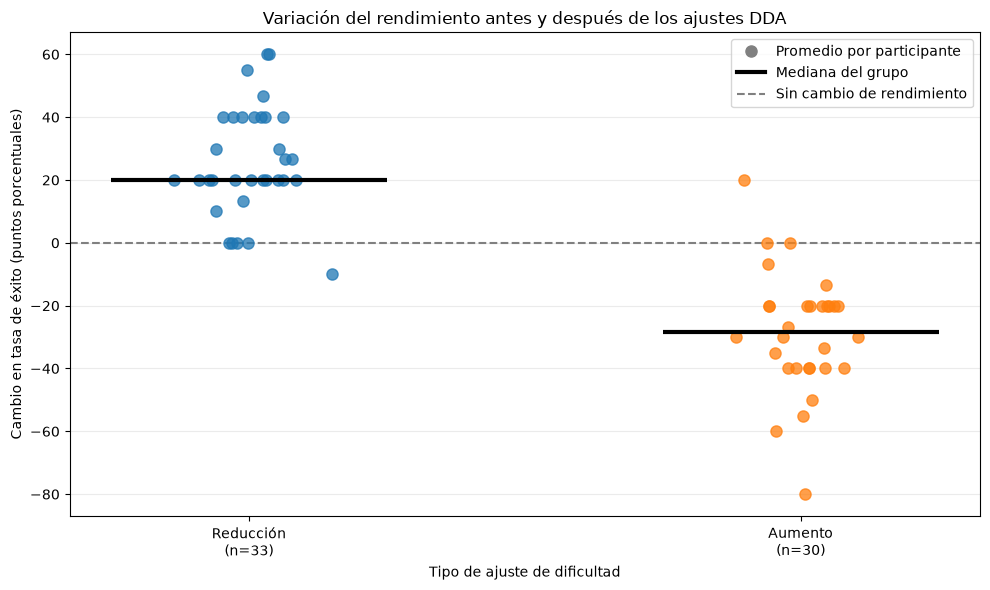

In [47]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

# Calcular diferencia promedio por participante y tipo de cambio
dda_participantes = (
    ventanas_validas
    .groupby(["Participante", "TipoCambio"], as_index=False)
    .agg(
        Cambios=("IdCambio", "count"),
        DiferenciaPromedio_pp=("Diferencia_pp", "mean")
    )
)

orden = ["Reducción", "Aumento"]

fig, ax = plt.subplots(figsize=(10, 6))

rng = np.random.default_rng(42)
etiquetas_x = []

for i, tipo in enumerate(orden):

    datos = dda_participantes.loc[
        dda_participantes["TipoCambio"] == tipo,
        "DiferenciaPromedio_pp"
    ].dropna()

    n = len(datos)
    etiquetas_x.append(f"{tipo}\n(n={n})")

    # Dispersión horizontal
    x = rng.normal(i, 0.07, size=n)

    ax.scatter(
        x,
        datos,
        s=65,
        alpha=0.75,
        zorder=3
    )

    # Mediana
    if n > 0:
        ax.hlines(
            datos.median(),
            i - 0.25,
            i + 0.25,
            linewidth=3,
            color="black",
            zorder=4
        )

# Línea de referencia: sin cambios en el rendimiento
ax.axhline(
    0,
    linestyle="--",
    linewidth=1.5,
    color="gray"
)

ax.set_xticks(range(len(orden)))
ax.set_xticklabels(etiquetas_x)

ax.set_xlabel("Tipo de ajuste de dificultad")
ax.set_ylabel("Cambio en tasa de éxito (puntos porcentuales)")

ax.set_title(
    "Variación del rendimiento antes y después de los ajustes DDA"
)

ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

leyenda = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markersize=8,
        color="gray",
        label="Promedio por participante"
    ),
    Line2D(
        [0], [0],
        linestyle="-",
        linewidth=3,
        color="black",
        label="Mediana del grupo"
    ),
    Line2D(
        [0], [0],
        linestyle="--",
        color="gray",
        label="Sin cambio de rendimiento"
    )
]

ax.legend(handles=leyenda, loc="best")

plt.tight_layout()
plt.show()

In [48]:
import pandas as pd

# Métricas que queremos revisar
metricas = [
    "TiempoEsperado_s",
    "TiempoReal_s",
    "DesfaseTiming_s",
    "ErrorTiming_s",
    "TiempoReaccion_s",
    "PrecisionEspacial",
    "PrecisionDireccion",
    "ManoCorrecta"
]

# Copiar las columnas necesarias
df_metricas = df_final[
    ["Minijuego", "TipoAccion"] + metricas
].copy()

# Verificar si existe un valor válido
def tiene_valor(valor):
    if pd.isna(valor):
        return False

    return str(valor).strip().lower() not in [
        "", "n/a", "nan", "none", "null"
    ]

# Convertir las métricas a True/False
for metrica in metricas:
    df_metricas[metrica] = (
        df_metricas[metrica].map(tiene_valor)
    )

# Agrupar por minijuego y tipo de interacción
tabla_metricas = (
    df_metricas
    .groupby(["Minijuego", "TipoAccion"])[metricas]
    .any()
    .reset_index()
)

# Marcar métricas disponibles con X
tabla_metricas[metricas] = (
    tabla_metricas[metricas].replace({
        True: "X",
        False: ""
    })
)

# Renombrar para presentación
tabla_metricas = tabla_metricas.rename(
    columns={"TipoAccion": "Interaccion"}
)

display(tabla_metricas)

,Minijuego,Interaccion,TiempoEsperado_s,TiempoReal_s,DesfaseTiming_s,ErrorTiming_s,TiempoReaccion_s,PrecisionEspacial,PrecisionDireccion,ManoCorrecta
0,Alex,HammerHit,X,X,X,X,,,,
1,Alex,HammerTouch,X,,,,,,,
2,Danniel,GunShoot,X,X,X,X,,,,
3,Danniel,PlayerHit,X,,,,,,,
4,Jeremy,SwordCut,X,X,X,X,,,X,X
5,Joaquin,GuitarHit,X,X,X,X,,,,
6,Joaquin,PlayerHit,X,,,,,,,
7,JuanAndres,GroomStroke,X,X,X,X,,,X,X
8,Shipi,FoodClear,X,,,,,,,
9,Shipi,FoodCut,X,X,X,X,X,,X,


In [49]:
columnas = ["Minijuego", "Interaccion"] + metricas

for _, fila in tabla_metricas.iterrows():
    valores = [
        str(fila[col]) if str(fila[col]).strip() else "---"
        for col in columnas
    ]

    print(" & ".join(valores) + r" \\ \hline")

Alex & HammerHit & X & X & X & X & --- & --- & --- & --- \\ \hline
Alex & HammerTouch & X & --- & --- & --- & --- & --- & --- & --- \\ \hline
Danniel & GunShoot & X & X & X & X & --- & --- & --- & --- \\ \hline
Danniel & PlayerHit & X & --- & --- & --- & --- & --- & --- & --- \\ \hline
Jeremy & SwordCut & X & X & X & X & --- & --- & X & X \\ \hline
Joaquin & GuitarHit & X & X & X & X & --- & --- & --- & --- \\ \hline
Joaquin & PlayerHit & X & --- & --- & --- & --- & --- & --- & --- \\ \hline
JuanAndres & GroomStroke & X & X & X & X & --- & --- & X & X \\ \hline
Shipi & FoodClear & X & --- & --- & --- & --- & --- & --- & --- \\ \hline
Shipi & FoodCut & X & X & X & X & X & --- & X & --- \\ \hline
